# CLRerNet (DLA34, CULane, EMA) — accuracy, GPU latency, per-part profiling, FLOPs / memory, graph & ONNX export

This notebook evaluates the official **CLRerNet⋆ (DLA34 + EMA)** checkpoint on the **CULane test set** on a Colab GPU and collects the numbers you need before deploying to a **Jetson Orin Nano**:

| Section | What you get |
|---|---|
| 1. Setup | GPU check, Google Drive, dataset copied to local disk |
| 2. Model | Stand-alone PyTorch CLRerNet that loads `clrernet_culane_dla34_ema.pth` with `strict=True` (no mmcv/mmdet build needed) |
| 3. Accuracy | Official CULane metric (F1 @ IoU 0.1/0.5/0.75 + 9 scenario categories), FP32 and FP16 |
| 4. Latency | Network latency (FP32/FP16, eager vs CUDA Graph), end-to-end per-frame pipeline breakdown, throughput vs batch size |
| 5. Per-part runtime | CUDA-event timing of every block (stem, DLA levels, FPN, each refine stage → ROI pooling / ROI-gather convs / cross-attention / FC heads / anchor decode), `torch.profiler` kernel breakdown + Chrome trace |
| 6. Complexity | Parameters, FLOPs/MACs, memory traffic (bytes moved), arithmetic intensity & roofline for T4 vs Orin Nano, peak GPU memory |
| 7. Graph | Layer summary, profiled block diagram, ONNX op histogram (open the `.onnx` in Netron for the full graph) |
| 8. ONNX | Export (opset 17), check, simplify, numerical check with ONNX Runtime, ORT GPU latency |
| 9. TensorRT (optional) | FP32/FP16 engines on the Colab GPU with per-layer profile grouped into the same parts |
| 10. Summary | Everything saved as JSON/CSV to Drive for later comparison with the Jetson |

**Runtime:** `Runtime → Change runtime type → T4 GPU`. Then `Run all`. Full test-set evaluation (34,680 images, FP32 + FP16) takes roughly 30–50 min on the free tier, most of it copying from Drive and running the CPU-side CULane metric; set `EVAL_SUBSET` below for a quick pass.

**Why no mmdetection?** The repo targets mmcv 2.x / mmdet 3.3 plus a custom CUDA NMS extension; Colab's current PyTorch has no prebuilt mmcv wheels, so that route needs a long source build. Instead, the model code below is a module-for-module copy of `libs/models/...` with identical parameter names (all 302 checkpoint tensors load with `strict=True`), the lane NMS is a NumPy port of `libs/models/layers/nms/src/nms_kernel.cu`, and pre/post-processing and the metric are copied from `culane_dataset.py`, `clrernet_head.py`, `lane_utils.py` and `culane_metric.py`. This plain-PyTorch form is also what exports cleanly to ONNX/TensorRT for the Jetson.

**Verification done before handing this over:** an independent NumPy implementation of the same network, run with these weights and this exact post-processing/metric code, reproduces the repo's `demo/result.png` lanes and scores F1@0.5 = 85.1 on a 125-image stratified sample of your test set (normal 97.8, crowd 82.8, night 78.1, curve 78.7). The self-test cell in section 2 re-checks the PyTorch port against two reference frames from that run, so you know immediately if anything differs on Colab.

## 1. Setup

In [1]:
!nvidia-smi
!pip -q install onnx onnxscript onnxruntime-gpu onnxslim torchinfo 2>&1 | tail -n 2

Fri Oct 16 15:02:30 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   61C    P8             11W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [2]:
import os, sys, json, time, math, glob, shutil, random, platform, subprocess, warnings
from pathlib import Path
from collections import defaultdict, OrderedDict
import numpy as np, pandas as pd, cv2, torch
import matplotlib.pyplot as plt
from tqdm.auto import tqdm
warnings.filterwarnings("ignore", category=UserWarning)

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
torch.backends.cudnn.benchmark = True
ENV = dict(python=platform.python_version(), torch=torch.__version__, cuda=torch.version.cuda,
           cudnn=torch.backends.cudnn.version(), cpu_count=os.cpu_count(),
           gpu=torch.cuda.get_device_name(0) if DEVICE == "cuda" else None)
if DEVICE == "cuda":
    p = torch.cuda.get_device_properties(0)
    ENV.update(gpu_mem_GB=round(p.total_memory / 1e9, 1), sm_count=p.multi_processor_count,
               compute_capability=f"{p.major}.{p.minor}")
else:
    print("WARNING: no GPU runtime -> Runtime > Change runtime type > T4 GPU")
print(json.dumps(ENV, indent=1))

{
 "python": "3.13.15",
 "torch": "2.11.0+cu130",
 "cuda": "13.0",
 "cudnn": 92700,
 "cpu_count": 2,
 "gpu": "Tesla T4",
 "gpu_mem_GB": 15.6,
 "sm_count": 40,
 "compute_capability": "7.5"
}


In [3]:
from google.colab import drive
drive.mount("/content/drive")

# ---------------------------------------------------------------- paths (edit if auto-detect fails)
DRIVE_ROOT       = "/content/drive/MyDrive"
CKPT_PATH        = "/content/drive/MyDrive/clrernet_culane_dla34_ema.pth"   # e.g. "/content/drive/MyDrive/CLRerNet CULane Lane Detection/clrernet_culane_dla34_ema.pth"
CULANE_DRIVE_DIR = "/content/drive/MyDrive/CULane_test_eval"   # e.g. "/content/drive/MyDrive/CULane_test_eval"  (contains driver_*/ and list/)
CULANE_ARCHIVE = "/content/drive/MyDrive/CULane_test_eval.tar"   # optional: a .zip/.tar of that folder on Drive (much faster to copy than 69k small files)
RESULTS_DIR      = "/content/drive/MyDrive/clrernet_profiling"   # all outputs are saved here
LOCAL_DATA       = "/content/CULane_test_eval"                   # local copy used for evaluation

# ---------------------------------------------------------------- run options
EVAL_SUBSET   = None   # None = full 34,680-image test set; int N = N images sampled per category (quick run)
EVAL_FP16     = True   # also evaluate accuracy with FP16 autocast (what you'll likely run on the Jetson)
BATCH_EVAL    = 32
LAT_WARMUP, LAT_ITERS = 50, 300
OPSET         = 17     # use 16 for TensorRT < 8.6 (LayerNorm gets decomposed)
SEED = 0

def _find(root, max_depth=4, want_file=None, want_dir_check=None, want_archive=False):
    hits = []
    root_depth = root.rstrip("/").count("/")
    for d, dirs, files in os.walk(root):
        depth = d.count("/") - root_depth
        dirs[:] = [x for x in dirs if not x.startswith((".", "driver_")) and depth < max_depth]
        if want_file and want_file in files:
            hits.append(os.path.join(d, want_file))
        if want_dir_check and want_dir_check(d):
            hits.append(d)
        if want_archive:
            hits += [os.path.join(d, f) for f in files if "culane" in f.lower() and f.lower().endswith((".zip", ".tar", ".tar.gz", ".tgz"))]
    return hits

SEARCH_ROOTS = [r for r in (DRIVE_ROOT, "/content/drive/Othercomputers", "/content/drive/Shareddrives") if os.path.isdir(r)]
def _find_all(**kw):
    return [h for r in SEARCH_ROOTS for h in _find(r, max_depth=6 if r != DRIVE_ROOT else 4, **kw)]

if CKPT_PATH is None:
    c = _find_all(want_file="clrernet_culane_dla34_ema.pth")
    assert c, "checkpoint not found on Drive - set CKPT_PATH"
    CKPT_PATH = c[0]
if CULANE_DRIVE_DIR is None and CULANE_ARCHIVE is None:
    c = _find_all(want_dir_check=lambda d: os.path.isfile(os.path.join(d, "list", "test.txt"))
              and os.path.isdir(os.path.join(d, "list", "test_split")))
    if c:
        CULANE_DRIVE_DIR = c[0]
    else:
        a = _find_all(want_archive=True)
        assert a, "CULane test folder not found on Drive - set CULANE_DRIVE_DIR or CULANE_ARCHIVE"
        CULANE_ARCHIVE = a[0]
os.makedirs(RESULTS_DIR, exist_ok=True)
print("checkpoint :", CKPT_PATH, f"({os.path.getsize(CKPT_PATH)/1e6:.1f} MB)")
print("CULane     :", CULANE_DRIVE_DIR or CULANE_ARCHIVE)
print("results    :", RESULTS_DIR)

Mounted at /content/drive
checkpoint : /content/drive/MyDrive/clrernet_culane_dla34_ema.pth (63.5 MB)
CULane     : /content/drive/MyDrive/CULane_test_eval
results    : /content/drive/MyDrive/clrernet_profiling


### Copy the test set to the local disk
Reading 69k small files through the Drive mount inside the evaluation loop is very slow, so the needed images + `.lines.txt` labels are copied once to `/content` with many parallel threads (skips files that already exist, so re-running is cheap). If you later upload the folder as a single `.zip`, set `CULANE_ARCHIVE` – that is several times faster.

In [4]:
# ---- get the CULane test set onto the local disk from the single .tar on Drive ----
LOCAL_TAR = "/content/CULane_test_eval.tar"
DONE_FLAG = os.path.join(LOCAL_DATA, ".extracted_ok")

def read_list(p):
    with open(p) as f:
        return [l.strip().split()[0].lstrip("/") for l in f if l.strip()]

assert CULANE_ARCHIVE and os.path.isfile(CULANE_ARCHIVE), f"archive not found: {CULANE_ARCHIVE}"

if not os.path.exists(DONE_FLAG):
    size_gb = os.path.getsize(CULANE_ARCHIVE) / 1e9
    print(f"archive on Drive: {size_gb:.1f} GB | local free disk: {shutil.disk_usage('/content').free/1e9:.0f} GB")

    # 1) one big sequential copy Drive -> local disk (fast, unlike 69k small files)
    t0 = time.time()
    subprocess.run(["rsync", "-ah", "--info=progress2", CULANE_ARCHIVE, LOCAL_TAR], check=True)
    print(f"copied in {time.time()-t0:.0f}s")

    # 2) extract locally
    t0 = time.time()
    shutil.rmtree("/content/_culane_extract", ignore_errors=True)
    os.makedirs("/content/_culane_extract")
    subprocess.run(["tar", "-xf", LOCAL_TAR, "-C", "/content/_culane_extract"], check=True)
    root = glob.glob("/content/_culane_extract/**/list/test.txt", recursive=True)[0]
    shutil.rmtree(LOCAL_DATA, ignore_errors=True)
    shutil.move(str(Path(root).parent.parent), LOCAL_DATA)
    os.remove(LOCAL_TAR)                       # free the disk space
    print(f"extracted in {time.time()-t0:.0f}s -> {LOCAL_DATA}")
    open(DONE_FLAG, "w").close()
else:
    print("already extracted in this session:", LOCAL_DATA)

SRC = LOCAL_DATA
ALL_TEST = read_list(os.path.join(LOCAL_DATA, "list", "test.txt"))
CATEGORIES = ['test0_normal', 'test1_crowd', 'test2_hlight', 'test3_shadow', 'test4_noline',
              'test5_arrow', 'test6_curve', 'test7_cross', 'test8_night']
CAT_LISTS = {c: read_list(os.path.join(LOCAL_DATA, "list", "test_split", c + ".txt")) for c in CATEGORIES}
print(f"test.txt: {len(ALL_TEST)} images;", {c: len(v) for c, v in CAT_LISTS.items()})

# completeness check: every listed image and its label must exist
missing_img = [p for p in ALL_TEST if not os.path.exists(os.path.join(LOCAL_DATA, p))]
missing_lbl = [p for p in ALL_TEST if not os.path.exists(os.path.join(LOCAL_DATA, p.replace(".jpg", ".lines.txt")))]
print(f"missing images: {len(missing_img)} | missing labels: {len(missing_lbl)}", missing_img[:3])

if EVAL_SUBSET:
    rng = random.Random(SEED)
    EVAL_LIST = sorted({p for c in CATEGORIES for p in rng.sample(CAT_LISTS[c], min(EVAL_SUBSET, len(CAT_LISTS[c])))})
else:
    EVAL_LIST = ALL_TEST
EVAL_LIST = [p for p in EVAL_LIST if os.path.exists(os.path.join(LOCAL_DATA, p))]
print("ready:", len(EVAL_LIST), "images")

archive on Drive: 10.8 GB | local free disk: 75 GB
copied in 286s
extracted in 62s -> /content/CULane_test_eval
test.txt: 34680 images; {'test0_normal': 9621, 'test1_crowd': 8113, 'test2_hlight': 486, 'test3_shadow': 930, 'test4_noline': 4067, 'test5_arrow': 890, 'test6_curve': 422, 'test7_cross': 3122, 'test8_night': 7029}
missing images: 0 | missing labels: 0 []
ready: 34680 images


## 2. Model (stand-alone PyTorch) and post-processing
`%%writefile` turns each cell into a module so the DataLoader / multiprocessing workers can import it.

In [5]:
%%writefile clrernet_standalone.py
# ===== CLRerNet (DLA34) – standalone, inference-only PyTorch re-implementation =====
# Mirrors hirotomusiker/CLRerNet (libs/models/...) module-for-module so the official
# checkpoint loads with strict=True, but without mmcv / mmdet / the CUDA NMS extension.
# Every block is wrapped in SECTION(...) so we can time / count FLOPs / bytes per part.
import math
import time
from collections import defaultdict
from contextlib import contextmanager, nullcontext

import torch
import torch.nn as nn
import torch.nn.functional as F

BN_MOMENTUM = 0.1


# ----------------------------------------------------------------------------- profiling hook
class SectionRecorder:
    """Hierarchical named sections around blocks of the forward pass.
    Disabled (default) -> zero cost, so the same model is used for eval / export.
    Enabled -> CUDA events per section (perf_counter on CPU); optionally also
    torch.profiler.record_function labels and NVTX ranges (for Nsight Systems)."""

    def __init__(self):
        self.enabled = False
        self.use_record_function = False
        self.use_nvtx = False
        self.stack = []
        self.pending = []
        self.times = defaultdict(list)      # "backbone/level3" -> [ms, ...]
        self.order = {}                     # first-seen order (= forward order)

    @property
    def current(self):
        return "/".join(self.stack)

    @contextmanager
    def __call__(self, name):
        if not self.enabled:
            yield
            return
        self.stack.append(name)
        full = self.current
        self.order.setdefault(full, len(self.order))
        use_cuda = torch.cuda.is_available() and torch.cuda.is_current_stream_capturing() is False
        if use_cuda:
            s = torch.cuda.Event(enable_timing=True)
            e = torch.cuda.Event(enable_timing=True)
            s.record()
        else:
            s, e = time.perf_counter(), None
        if self.use_nvtx and use_cuda:
            torch.cuda.nvtx.range_push(full)
        ctx = torch.profiler.record_function(full) if self.use_record_function else nullcontext()
        try:
            with ctx:
                yield
        finally:
            if self.use_nvtx and use_cuda:
                torch.cuda.nvtx.range_pop()
            if e is not None:
                e.record()
                self.pending.append((full, s, e))
            else:
                self.times[full].append((time.perf_counter() - s) * 1e3)
            self.stack.pop()

    def collect(self):
        if self.pending:
            torch.cuda.synchronize()
            for full, s, e in self.pending:
                self.times[full].append(s.elapsed_time(e))
            self.pending.clear()

    def reset(self):
        self.pending.clear()
        self.times.clear()
        self.stack.clear()


SECTION = SectionRecorder()


# ----------------------------------------------------------------------------- DLA-34 backbone
class BasicBlock(nn.Module):
    def __init__(self, inplanes, planes, stride=1, dilation=1):
        super().__init__()
        self.conv1 = nn.Conv2d(inplanes, planes, 3, stride=stride, padding=dilation, bias=False, dilation=dilation)
        self.bn1 = nn.BatchNorm2d(planes, momentum=BN_MOMENTUM)
        self.relu = nn.ReLU(inplace=True)
        self.conv2 = nn.Conv2d(planes, planes, 3, stride=1, padding=dilation, bias=False, dilation=dilation)
        self.bn2 = nn.BatchNorm2d(planes, momentum=BN_MOMENTUM)
        self.stride = stride

    def forward(self, x, residual=None):
        if residual is None:
            residual = x
        out = self.relu(self.bn1(self.conv1(x)))
        out = self.bn2(self.conv2(out))
        out = out + residual
        return self.relu(out)


class Root(nn.Module):
    def __init__(self, in_channels, out_channels, kernel_size, residual):
        super().__init__()
        self.conv = nn.Conv2d(in_channels, out_channels, 1, stride=1, bias=False, padding=(kernel_size - 1) // 2)
        self.bn = nn.BatchNorm2d(out_channels, momentum=BN_MOMENTUM)
        self.relu = nn.ReLU(inplace=True)
        self.residual = residual

    def forward(self, *x):
        children = x
        x = self.bn(self.conv(torch.cat(x, 1)))
        if self.residual:
            x = x + children[0]
        return self.relu(x)


class Tree(nn.Module):
    def __init__(self, levels, block, in_channels, out_channels, stride=1, level_root=False,
                 root_dim=0, root_kernel_size=1, dilation=1, root_residual=False):
        super().__init__()
        if root_dim == 0:
            root_dim = 2 * out_channels
        if level_root:
            root_dim += in_channels
        if levels == 1:
            self.tree1 = block(in_channels, out_channels, stride, dilation=dilation)
            self.tree2 = block(out_channels, out_channels, 1, dilation=dilation)
        else:
            self.tree1 = Tree(levels - 1, block, in_channels, out_channels, stride, root_dim=0,
                              root_kernel_size=root_kernel_size, dilation=dilation, root_residual=root_residual)
            self.tree2 = Tree(levels - 1, block, out_channels, out_channels, root_dim=root_dim + out_channels,
                              root_kernel_size=root_kernel_size, dilation=dilation, root_residual=root_residual)
        if levels == 1:
            self.root = Root(root_dim, out_channels, root_kernel_size, root_residual)
        self.level_root = level_root
        self.root_dim = root_dim
        self.downsample = nn.MaxPool2d(stride, stride=stride) if stride > 1 else None
        self.project = None
        self.levels = levels
        if levels == 1 and in_channels != out_channels:
            self.project = nn.Sequential(
                nn.Conv2d(in_channels, out_channels, kernel_size=1, stride=1, bias=False),
                nn.BatchNorm2d(out_channels, momentum=BN_MOMENTUM))

    def forward(self, x, residual=None, children=None):
        children = [] if children is None else children
        bottom = self.downsample(x) if self.downsample is not None else x
        residual = self.project(bottom) if self.project is not None else bottom
        if self.level_root:
            children.append(bottom)
        x1 = self.tree1(x, residual)
        if self.levels == 1:
            x2 = self.tree2(x1)
            x = self.root(x2, x1, *children)
        else:
            children.append(x1)
            x = self.tree2(x1, children=children)
        return x


class DLA(nn.Module):
    def __init__(self, levels, channels, block=BasicBlock, out_indices=(2, 3, 4, 5), residual_root=False):
        super().__init__()
        self.channels = channels
        self.out_indices = out_indices
        self.base_layer = nn.Sequential(
            nn.Conv2d(3, channels[0], kernel_size=7, stride=1, padding=3, bias=False),
            nn.BatchNorm2d(channels[0], momentum=BN_MOMENTUM),
            nn.ReLU(inplace=True))
        self.level0 = self._make_conv_level(channels[0], channels[0], levels[0])
        self.level1 = self._make_conv_level(channels[0], channels[1], levels[1], stride=2)
        self.level2 = Tree(levels[2], block, channels[1], channels[2], 2, level_root=False, root_residual=residual_root)
        self.level3 = Tree(levels[3], block, channels[2], channels[3], 2, level_root=True, root_residual=residual_root)
        self.level4 = Tree(levels[4], block, channels[3], channels[4], 2, level_root=True, root_residual=residual_root)
        self.level5 = Tree(levels[5], block, channels[4], channels[5], 2, level_root=True, root_residual=residual_root)

    @staticmethod
    def _make_conv_level(inplanes, planes, convs, stride=1, dilation=1):
        modules = []
        for i in range(convs):
            modules.extend([
                nn.Conv2d(inplanes, planes, kernel_size=3, stride=stride if i == 0 else 1,
                          padding=dilation, bias=False, dilation=dilation),
                nn.BatchNorm2d(planes, momentum=BN_MOMENTUM),
                nn.ReLU(inplace=True)])
            inplanes = planes
        return nn.Sequential(*modules)

    def forward(self, x):
        y = []
        with SECTION("base_layer"):
            x = self.base_layer(x)
        for i in range(6):
            with SECTION(f"level{i}"):
                x = getattr(self, f"level{i}")(x)
            if i in self.out_indices:
                y.append(x)
        return y


class DLANet(nn.Module):
    def __init__(self, levels=(1, 1, 1, 2, 2, 1), in_channels=(16, 32, 64, 128, 256, 512)):
        super().__init__()
        self.model = DLA(levels=list(levels), channels=list(in_channels), block=BasicBlock)

    def forward(self, x):
        return self.model(x)


# ----------------------------------------------------------------------------- mmcv ConvModule (minimal)
class ConvModule(nn.Module):
    """conv -> (bn) -> (relu); parameter names match mmcv.cnn.ConvModule."""

    def __init__(self, in_channels, out_channels, kernel_size, padding=0, bias="auto", norm=False, act=True):
        super().__init__()
        if bias == "auto":
            bias = not norm
        self.with_norm, self.with_act = norm, act
        self.conv = nn.Conv2d(in_channels, out_channels, kernel_size, padding=padding, bias=bias)
        if norm:
            self.bn = nn.BatchNorm2d(out_channels)
        if act:
            self.activate = nn.ReLU(inplace=True)

    def forward(self, x):
        x = self.conv(x)
        if self.with_norm:
            x = self.bn(x)
        if self.with_act:
            x = self.activate(x)
        return x


# ----------------------------------------------------------------------------- FPN neck
class CLRerNetFPN(nn.Module):
    def __init__(self, in_channels=(128, 256, 512), out_channels=64):
        super().__init__()
        self.in_channels = list(in_channels)
        self.lateral_convs = nn.ModuleList()
        self.fpn_convs = nn.ModuleList()
        for c in in_channels:
            self.lateral_convs.append(ConvModule(c, out_channels, 1, norm=False, act=False))
            self.fpn_convs.append(ConvModule(out_channels, out_channels, 3, padding=1, norm=False, act=False))

    def forward(self, inputs):
        inputs = list(inputs)[-len(self.in_channels):]          # drop level2 output (stride 4)
        with SECTION("lateral_1x1"):
            laterals = [l(inputs[i]) for i, l in enumerate(self.lateral_convs)]
        with SECTION("top_down"):
            for i in range(len(laterals) - 1, 0, -1):
                laterals[i - 1] = laterals[i - 1] + F.interpolate(laterals[i], size=laterals[i - 1].shape[2:],
                                                                  mode="nearest")
        with SECTION("fpn_3x3"):
            outs = [self.fpn_convs[i](laterals[i]) for i in range(len(laterals))]
        return tuple(outs)


# ----------------------------------------------------------------------------- head pieces
class FeatureResize(nn.Module):
    def __init__(self, size=(10, 25)):
        super().__init__()
        self.size = size

    def forward(self, x):
        return F.interpolate(x, self.size).flatten(2)


class AnchorVecFeatureMapAttention(nn.Module):
    def __init__(self, n_query, dim):
        super().__init__()
        self.dim = dim
        self.resize = FeatureResize()
        self.f_key = ConvModule(dim, dim, 1, norm=True, act=True)
        self.f_query = nn.Sequential(nn.Conv1d(n_query, n_query, 1, groups=n_query), nn.ReLU())
        self.f_value = nn.Conv2d(dim, dim, 1)
        self.W = nn.Conv1d(n_query, n_query, 1, groups=n_query)

    def forward(self, roi, fmap):
        query = self.f_query(roi)                                 # [B, Np, C]
        key = self.resize(self.f_key(fmap))                       # [B, C, 250]
        value = self.resize(self.f_value(fmap)).permute(0, 2, 1)  # [B, 250, C]
        sim_map = F.softmax((self.dim ** -0.5) * torch.matmul(query, key), dim=-1)
        context = torch.matmul(sim_map, value)                    # [B, Np, C]
        return self.W(context)


class ROIGather(nn.Module):
    def __init__(self, in_channels=64, num_priors=192, sample_points=36, fc_hidden_dim=64,
                 refine_layers=3, mid_channels=48):
        super().__init__()
        self.in_channels = in_channels
        self.num_priors = num_priors
        self.attention = AnchorVecFeatureMapAttention(num_priors, in_channels)
        self.convs = nn.ModuleList()
        self.catconv = nn.ModuleList()
        for i in range(refine_layers):
            self.convs.append(ConvModule(in_channels, mid_channels, (9, 1), padding=(4, 0), bias=False, norm=True))
            self.catconv.append(ConvModule(mid_channels * (i + 1), in_channels, (9, 1), padding=(4, 0),
                                           bias=False, norm=True))
        self.fc = nn.Linear(sample_points * in_channels, fc_hidden_dim)
        self.fc_norm = nn.LayerNorm(fc_hidden_dim)

    def forward(self, roi_features, fmap, layer_index):
        bs = fmap.size(0)
        with SECTION("roi_conv_fc"):
            feats = [self.convs[i](f) for i, f in enumerate(roi_features)]
            roi = self.catconv[layer_index](torch.cat(feats, dim=1))
            roi = roi.reshape(bs * self.num_priors, -1)
            roi = F.relu(self.fc_norm(self.fc(roi))).reshape(bs, self.num_priors, -1)
        with SECTION("cross_attention"):
            roi = roi + self.attention(roi, fmap)                 # dropout = identity at inference
        return roi


class CLRerNetAnchorGenerator(nn.Module):
    def __init__(self, num_priors=192, num_points=72):
        super().__init__()
        self.num_priors = num_priors
        self.num_offsets = num_points
        self.prior_embeddings = nn.Embedding(num_priors, 3)     # learned (y0, x0, theta), loaded from ckpt

    def generate_anchors(self, anchor_params, prior_ys, sample_x_indices, img_w, img_h):
        """anchor_params [..., 3] -> anchor xs [..., 72] and sampled xs [..., 36] (normalised)."""
        x0 = anchor_params[..., 1:2] * (img_w - 1)
        y0 = anchor_params[..., 0:1]
        theta = anchor_params[..., 2:3] * math.pi
        tan_lane = torch.tan(theta + 1e-5)
        anchor_xs = (x0 - (prior_ys - y0) * img_h / tan_lane) / (img_w - 1)
        sampled_xs = torch.index_select(anchor_xs, -1, sample_x_indices)
        return anchor_xs, sampled_xs


class CLRerHead(nn.Module):
    def __init__(self, img_w=800, img_h=320, num_priors=192, num_points=72, prior_feat_channels=64,
                 fc_hidden_dim=64, num_fc=2, refine_layers=3, sample_points=36):
        super().__init__()
        self.anchor_generator = CLRerNetAnchorGenerator(num_priors, num_points)
        self.img_w, self.img_h = img_w, img_h
        self.n_offsets = num_points
        self.n_strips = num_points - 1
        self.num_priors = num_priors
        self.sample_points = sample_points
        self.refine_layers = refine_layers
        self.fc_hidden_dim = fc_hidden_dim
        self.prior_feat_channels = prior_feat_channels
        self.register_buffer("sample_x_indices",
                             (torch.linspace(0, 1, steps=sample_points, dtype=torch.float32) * self.n_strips).long())
        self.register_buffer("prior_feat_ys", torch.flip((self.sample_x_indices.float() / self.n_strips), dims=[-1]))
        self.register_buffer("prior_ys", torch.linspace(1, 0, steps=num_points, dtype=torch.float32))
        reg_modules, cls_modules = [], []
        for _ in range(num_fc):
            reg_modules += [nn.Linear(fc_hidden_dim, fc_hidden_dim), nn.ReLU(inplace=True)]
            cls_modules += [nn.Linear(fc_hidden_dim, fc_hidden_dim), nn.ReLU(inplace=True)]
        self.reg_modules = nn.ModuleList(reg_modules)
        self.cls_modules = nn.ModuleList(cls_modules)
        self.reg_layers = nn.Linear(fc_hidden_dim, num_points + 4)
        self.cls_layers = nn.Linear(fc_hidden_dim, 2)
        self.attention = ROIGather(prior_feat_channels, num_priors, sample_points, fc_hidden_dim, refine_layers)

    def pool_prior_features(self, batch_features, prior_xs):
        """grid_sample features along each prior: [B,C,H,W] x [B,Np,Ns] -> [B*Np, C, Ns, 1]."""
        b = batch_features.shape[0]
        prior_xs = prior_xs.reshape(b, self.num_priors, -1, 1)
        prior_ys = self.prior_feat_ys.reshape(1, 1, -1, 1).expand(b, self.num_priors, -1, 1)
        grid = torch.cat((prior_xs * 2.0 - 1.0, prior_ys * 2.0 - 1.0), dim=-1)
        feature = F.grid_sample(batch_features, grid, mode="bilinear", padding_mode="zeros",
                                align_corners=True).permute(0, 2, 1, 3)
        return feature.reshape(b * self.num_priors, self.prior_feat_channels, self.sample_points, 1)

    def forward(self, x, return_all_stages=False):
        b = x[0].shape[0]
        feature_pyramid = list(x[len(x) - self.refine_layers:])[::-1]   # [10x25, 20x50, 40x100]
        ag = self.anchor_generator
        with SECTION("anchor_init"):
            emb = ag.prior_embeddings.weight
            _, sampled_xs = ag.generate_anchors(emb, self.prior_ys, self.sample_x_indices, self.img_w, self.img_h)
            anchor_params = emb.unsqueeze(0).expand(b, -1, -1)               # [B, Np, 3]
            priors_on_featmap = sampled_xs.unsqueeze(0).expand(b, -1, -1)    # [B, Np, Ns]
        preds, pooled_stages = [], []
        for stage in range(self.refine_layers):
            with SECTION(f"stage{stage}"):
                with SECTION("roi_pool(grid_sample)"):
                    pooled_stages.append(self.pool_prior_features(feature_pyramid[stage], priors_on_featmap))
                fc_features = self.attention(pooled_stages, feature_pyramid[stage], stage)
                fc_features = fc_features.reshape(b * self.num_priors, self.fc_hidden_dim)
                with SECTION("cls_reg_fc"):
                    cls_f, reg_f = fc_features, fc_features
                    for m in self.cls_modules:
                        cls_f = m(cls_f)
                    for m in self.reg_modules:
                        reg_f = m(reg_f)
                    cls_logits = self.cls_layers(cls_f).reshape(b, -1, 2)
                    reg = self.reg_layers(reg_f).reshape(b, -1, self.n_offsets + 4)
                with SECTION("anchor_decode"):
                    anchor_params = anchor_params + reg[:, :, :3]
                    anchor_xs, sampled = ag.generate_anchors(anchor_params, self.prior_ys, self.sample_x_indices,
                                                             self.img_w, self.img_h)
                    xs = anchor_xs + reg[..., 4:]
                    preds.append((cls_logits, anchor_params, reg[:, :, 3:4], xs))
                    priors_on_featmap = sampled
        return preds if return_all_stages else preds[-1]


class CLRerNet(nn.Module):
    """Input: BGR float tensor in [0,1], shape [B,3,320,800] (rows 270:590 of the 1640x590 frame).
    Output (final refine stage): cls_logits [B,192,2], anchor_params [B,192,3], lengths [B,192,1], xs [B,192,72]."""

    def __init__(self):
        super().__init__()
        self.backbone = DLANet()
        self.neck = CLRerNetFPN()
        self.bbox_head = CLRerHead()

    def forward(self, img):
        with SECTION("backbone"):
            feats = self.backbone(img)
        with SECTION("neck"):
            feats = self.neck(feats)
        with SECTION("head"):
            return self.bbox_head(feats)


def load_clrernet(ckpt_path, device="cpu"):
    """Build the model and load the official checkpoint with strict=True."""
    model = CLRerNet()
    try:
        ck = torch.load(ckpt_path, map_location="cpu", weights_only=True)
    except Exception:
        ck = torch.load(ckpt_path, map_location="cpu", weights_only=False)
    sd = ck.get("state_dict", ck)
    sd = {k: v for k, v in sd.items() if not k.startswith("bbox_head.seg_decoder")}   # training-only aux head
    model.load_state_dict(sd, strict=True)
    return model.to(device).eval()

Writing clrernet_standalone.py


In [6]:
%%writefile clrernet_post.py
# ===== CLRerNet post-processing + CULane metric (pure numpy / scipy / cv2) =====
# Faithful port of: libs/models/dense_heads/clrernet_head.py (get_lanes, predictions_to_lanes),
# libs/models/layers/nms (CUDA lane NMS), libs/utils/lane_utils.py and
# libs/datasets/metrics/culane_metric.py.  Works on outputs of PyTorch, ONNX Runtime or TensorRT.
import os
from functools import partial
from pathlib import Path

import cv2
import numpy as np
from scipy.interpolate import InterpolatedUnivariateSpline, splev, splprep
from scipy.optimize import linear_sum_assignment

# ---- constants from configs/clrernet/base_clrernet.py + clrernet_culane_dla34_ema.py ----
IMG_W, IMG_H = 800, 320          # network input
ORI_W, ORI_H = 1640, 590         # CULane frame
CUT_HEIGHT = 270                 # rows cropped from the top
N_OFFSETS = 72                   # rows per lane
N_STRIPS = N_OFFSETS - 1
CONF_THRESHOLD = 0.43            # EMA model (0.41 for the non-EMA model)
NMS_THRES = 50                   # pixels (mean |dx| on the 800-wide input)
NMS_TOPK = 4
PRIOR_YS = np.linspace(1, 0, N_OFFSETS, dtype=np.float32)
CATEGORIES = ['test0_normal', 'test1_crowd', 'test2_hlight', 'test3_shadow', 'test4_noline',
              'test5_arrow', 'test6_curve', 'test7_cross', 'test8_night']


def preprocess_bgr(img_bgr):
    """Same as the repo test pipeline: crop rows 270:590, resize to 800x320 (bilinear),
    keep BGR order, scale to [0,1].  Returns float32 CHW."""
    img = img_bgr[CUT_HEIGHT:ORI_H, 0:ORI_W]
    img = cv2.resize(img, (IMG_W, IMG_H), interpolation=cv2.INTER_LINEAR)
    return np.ascontiguousarray(img.transpose(2, 0, 1), dtype=np.float32) / 255.0


def _dev_iou(a, b, thr):
    """Port of devIoU() in nms_kernel.cu (True -> b is suppressed by a)."""
    start_a = int(a[2] * N_STRIPS + 0.5)
    start_b = int(b[2] * N_STRIPS + 0.5)
    start = max(start_a, start_b)
    end_a = int(start_a + a[4] - 1 + 0.5 - (1 if (a[4] - 1) < 0 else 0))
    end_b = int(start_b + b[4] - 1 + 0.5 - (1 if (b[4] - 1) < 0 else 0))
    end = min(end_a, end_b, N_OFFSETS - 1)
    if end < start:
        return False
    dist = np.abs(a[5 + start:6 + end] - b[5 + start:6 + end]).sum()
    return dist < thr * (end - start + 1)


def lane_nms(boxes, scores, overlap=NMS_THRES, top_k=NMS_TOPK):
    """Greedy lane NMS, identical decision rule to the repo's CUDA extension.
    boxes: (N, 5+72) = [logit0, logit1, start_y, start_x, length, xs*799 ...]."""
    order = np.argsort(-scores, kind='stable')
    removed = np.zeros(len(order), dtype=bool)
    keep = []
    for ii, i in enumerate(order):
        if removed[ii]:
            continue
        keep.append(i)
        if len(keep) == top_k:
            break
        for jj in range(ii + 1, len(order)):
            if not removed[jj] and _dev_iou(boxes[i], boxes[order[jj]], overlap):
                removed[jj] = True
    return np.array(keep, dtype=np.int64)


class Lane:
    """lane_utils.Lane: cubic spline x(y) on normalised coords."""
    def __init__(self, points, invalid_value=-2.0, metadata=None):
        self.points = points
        self.invalid_value = invalid_value
        self.function = InterpolatedUnivariateSpline(points[:, 1], points[:, 0], k=min(3, len(points) - 1))
        self.min_y = points[:, 1].min() - 0.01
        self.max_y = points[:, 1].max() + 0.01
        self.metadata = metadata or {}

    def __call__(self, lane_ys):
        lane_xs = self.function(lane_ys)
        lane_xs[(lane_ys < self.min_y) | (lane_ys > self.max_y)] = self.invalid_value
        return lane_xs


def predictions_to_lanes(pred_xs, anchor_params, lengths, extend_bottom=True):
    prior_ys = PRIOR_YS.astype(np.float64)
    lanes = []
    for lane_xs, lane_param, length in zip(pred_xs, anchor_params, lengths):
        start = min(max(0, int(round((1 - float(lane_param[0])) * N_STRIPS))), N_STRIPS)
        length = int(round(float(length)))
        end = min(start + length - 1, len(prior_ys) - 1)
        if extend_bottom:
            edge = (lane_xs[:start] >= 0.0) & (lane_xs[:start] <= 1.0)
            start -= int(np.cumprod(edge[::-1]).sum())
        lane_ys = prior_ys[start:end + 1][::-1]
        lxs = lane_xs[start:end + 1].astype(np.float64)[::-1]
        lane_ys = (lane_ys * (ORI_H - CUT_HEIGHT) + CUT_HEIGHT) / ORI_H
        if len(lxs) <= 1:
            continue
        lanes.append(np.stack([lxs, lane_ys], axis=1))
    return lanes


def decode_one(cls_logits, anchor_params, lengths, xs, conf_threshold=CONF_THRESHOLD,
               use_nms=True, extend_bottom=True):
    """Decode ONE image (final refine stage) -> list of (N,2) normalised [x, y] arrays.
    cls_logits (192,2), anchor_params (192,3), lengths (192,1), xs (192,72)."""
    cls_logits = cls_logits.astype(np.float32)
    e = np.exp(cls_logits - cls_logits.max(-1, keepdims=True))
    scores = (e / e.sum(-1, keepdims=True))[:, 1]
    keep = scores >= conf_threshold
    if not keep.any():
        return [], np.zeros(0, np.float32)
    scores, xs, lengths, anchor_params = scores[keep], xs[keep], lengths[keep], anchor_params[keep]
    logits = cls_logits[keep]
    if use_nms:
        nms_preds = np.concatenate([
            logits,
            np.stack([1 - anchor_params[:, 0], anchor_params[:, 1]], axis=1),
            lengths * N_STRIPS,
            xs * (IMG_W - 1)], axis=1).astype(np.float32)
        k = lane_nms(nms_preds, scores)
        xs, scores, lengths, anchor_params = xs[k], scores[k], lengths[k], anchor_params[k]
    lengths = np.round(lengths * N_STRIPS)[:, 0]
    return predictions_to_lanes(xs, anchor_params, lengths, extend_bottom), scores


def lanes_to_culane_string(lanes, y_step=2):
    """CULaneMetric.get_prediction_string (spline-resampled every 2 px)."""
    ys = np.arange(0, ORI_H, y_step) / ORI_H
    out = []
    for pts in lanes:
        lane = Lane(pts)
        xs = lane(ys)
        valid = (xs >= 0) & (xs < 1)
        lane_xs = (xs * ORI_W)[valid][::-1]
        lane_ys = (ys[valid] * ORI_H)[::-1]
        if len(lane_xs) < 2:
            continue
        out.append(" ".join("{:.5f} {:.5f}".format(x, y) for x, y in zip(lane_xs, lane_ys)))
    return "\n".join(out)


def lanes_to_pixels(lanes, y_step=2):
    """Lanes in original-image pixel coords (for drawing)."""
    s = lanes_to_culane_string(lanes, y_step)
    return [np.array(list(map(float, l.split()))).reshape(-1, 2) for l in s.split("\n") if l.strip()]


# ------------------------------- CULane metric -------------------------------
def interp(points, n=5):
    x = [x for x, _ in points]
    y = [y for _, y in points]
    tck, u = splprep([x, y], s=0, t=5, k=min(3, len(points) - 1))
    u = np.linspace(0.0, 1.0, num=(len(u) - 1) * n + 1)
    return np.array(splev(u, tck)).T


def draw_lane(lane, img=None, img_shape=None, width=30, color=(255, 255, 255)):
    if img is None:
        img = np.zeros(img_shape, dtype=np.uint8)
    lane = lane.astype(np.int32)
    for p1, p2 in zip(lane[:-1], lane[1:]):
        cv2.line(img, tuple(int(v) for v in p1), tuple(int(v) for v in p2), color, thickness=width)
    return img


def discrete_cross_iou(xs, ys, width=30, img_shape=(590, 1640, 3)):
    xs = [draw_lane(lane, img_shape=img_shape, width=width) > 0 for lane in xs]
    ys = [draw_lane(lane, img_shape=img_shape, width=width) > 0 for lane in ys]
    ious = np.zeros((len(xs), len(ys)))
    for i, x in enumerate(xs):
        for j, y in enumerate(ys):
            ious[i, j] = (x & y).sum() / (x | y).sum()
    return ious


def culane_metric(pred, anno, cat, width=30, iou_thresholds=(0.5,), img_shape=(590, 1640, 3)):
    interp_pred = [interp(p, n=5) for p in pred]
    interp_anno = [interp(a, n=5) for a in anno]
    ious = discrete_cross_iou(interp_pred, interp_anno, width=width, img_shape=img_shape)
    row_ind, col_ind = linear_sum_assignment(1 - ious)
    pred_ious = np.zeros(len(pred))
    pred_ious[row_ind] = ious[row_ind, col_ind]
    return {'n_gt': len(anno), 'cat': cat, 'hits': [pred_ious > t for t in iou_thresholds]}


def load_culane_img_data(path):
    with open(path, 'r') as f:
        img_data = [list(map(float, line.split())) for line in f.readlines()]
    img_data = [[(lane[i], lane[i + 1]) for i in range(0, len(lane), 2)] for lane in img_data]
    return [lane for lane in img_data if len(lane) >= 2]


def load_categories(categories_dir):
    data_cats = {}
    for c in CATEGORIES:
        p = Path(categories_dir) / f"{c}.txt"
        if p.exists():
            with open(p) as f:
                data_cats.update({k.strip(): c for k in f if k.strip()})
    return data_cats


def _metric_job(args):
    pred_path, anno_path, cat, iou_thresholds = args
    return culane_metric(load_culane_img_data(pred_path), load_culane_img_data(anno_path), cat,
                         width=30, iou_thresholds=list(iou_thresholds))


def eval_predictions(pred_dir, anno_dir, rel_paths, categories_dir,
                     iou_thresholds=(0.1, 0.5, 0.75), workers=None, verbose=True):
    """rel_paths: list like 'driver_100_30frame/xxx.MP4/00000.jpg' (no leading slash)."""
    from multiprocessing import Pool
    data_cats = load_categories(categories_dir)
    jobs = []
    for p in rel_paths:
        txt = p.replace('.jpg', '.lines.txt')
        jobs.append((os.path.join(pred_dir, txt), os.path.join(anno_dir, txt),
                     data_cats.get(p, 'test0_normal'), tuple(iou_thresholds)))
    workers = workers or os.cpu_count()
    with Pool(workers) as pool:
        results = pool.map(_metric_job, jobs, chunksize=64)
    eps = 1e-8
    out = {}
    for k, thr in enumerate(iou_thresholds):
        for i in range(len(CATEGORIES) + 1):
            cats = CATEGORIES if i == 0 else [CATEGORIES[i - 1]]
            rs = [r for r in results if r['cat'] in cats]
            if not rs:
                continue
            n_gt = sum(r['n_gt'] for r in rs)
            hits = np.concatenate([r['hits'][k] for r in rs]) if rs else np.zeros(0, bool)
            tp = int(hits.sum()); fp = int(len(hits) - tp); fn = n_gt - tp
            prec = tp / (tp + fp + eps); rec = tp / (n_gt + eps); f1 = 2 * prec * rec / (prec + rec + eps)
            name = 'all' if i == 0 else cats[0]
            out[(thr, name)] = dict(N=len(rs), TP=tp, FP=fp, FN=fn, Precision=prec, Recall=rec, F1=f1)
            if verbose and (i == 0 or thr == 0.5):
                print(f"IoU={thr:<4} {name:13s} N={len(rs):5d} TP={tp:6d} FP={fp:6d} FN={fn:6d} "
                      f"P={prec:.4f} R={rec:.4f} F1={f1:.4f}")
    return out

Writing clrernet_post.py


loaded OK: 15.826 M parameters, conf_threshold=0.43


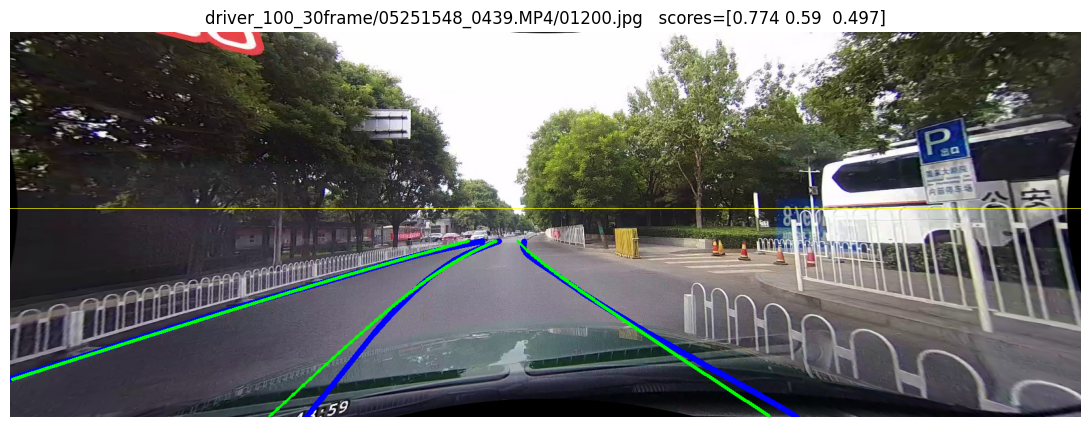

In [7]:
import importlib, clrernet_standalone as CS, clrernet_post as CP
importlib.reload(CS); importlib.reload(CP)
from clrernet_standalone import load_clrernet, SECTION
from clrernet_post import (preprocess_bgr, decode_one, lanes_to_culane_string, lanes_to_pixels,
                           eval_predictions, load_culane_img_data, CONF_THRESHOLD)

model = load_clrernet(CKPT_PATH, DEVICE)       # strict=True -> raises if any key/shape differs
n_params = sum(p.numel() for p in model.parameters())
print(f"loaded OK: {n_params/1e6:.3f} M parameters, conf_threshold={CONF_THRESHOLD}")

# quick visual sanity check on one test image: GT = blue, prediction = green
_ev = set(EVAL_LIST)
rel = ([p for p in CAT_LISTS["test6_curve"] if p in _ev] or EVAL_LIST)[0]
img = cv2.imread(os.path.join(LOCAL_DATA, rel))
with torch.inference_mode():
    out = model(torch.from_numpy(preprocess_bgr(img))[None].to(DEVICE))
cls, ap, ln, xs = [o[0].float().cpu().numpy() for o in out]
lanes, scores = decode_one(cls, ap, ln, xs)
vis = img.copy()
for gt in load_culane_img_data(os.path.join(LOCAL_DATA, rel.replace(".jpg", ".lines.txt"))):
    cv2.polylines(vis, [np.int32(gt)], False, (255, 0, 0), 8)
for pl in lanes_to_pixels(lanes):
    cv2.polylines(vis, [np.int32(pl)], False, (0, 255, 0), 4)
cv2.line(vis, (0, 270), (1640, 270), (0, 255, 255), 1)   # crop line: rows above are never seen by the network
plt.figure(figsize=(14, 5)); plt.imshow(vis[..., ::-1]); plt.axis("off")
plt.title(f"{rel}   scores={np.round(scores, 3)}"); plt.show()

### Self-test against reference outputs

In [8]:
# Self-test: the PyTorch port must reproduce a reference forward pass of the official weights
# (computed offline with an independent NumPy implementation of the same network + post-processing).
REFERENCE = {
    "driver_100_30frame/05251517_0433.MP4/01650.jpg": dict(top5_scores=[0.8952, 0.862, 0.8591, 0.8284, 0.8094],
                                                           lane_bottom_xy=[[513.5, 588.0], [0.2, 534.0], [1554.2, 588.0]]),
    "driver_100_30frame/05251548_0439.MP4/01200.jpg": dict(top5_scores=[0.7742, 0.7639, 0.7414, 0.5904, 0.5756],
                                                           lane_bottom_xy=[[3.9, 532.0], [1162.3, 588.0], [397.3, 588.0]]),
}
ok_all = True
for rel, ref in REFERENCE.items():
    dst = os.path.join(LOCAL_DATA, rel)
    if not os.path.exists(dst) and SRC != LOCAL_DATA:
        os.makedirs(os.path.dirname(dst), exist_ok=True); shutil.copyfile(os.path.join(SRC, rel), dst)
    with torch.inference_mode():
        o = [t[0].float().cpu().numpy() for t in model(torch.from_numpy(preprocess_bgr(cv2.imread(dst)))[None].to(DEVICE))]
    sc = np.exp(o[0] - o[0].max(1, keepdims=True)); sc = np.sort(sc[:, 1] / sc.sum(1))[::-1][:5]
    px = [l[0] for l in lanes_to_pixels(decode_one(*o)[0])]
    d_sc = np.abs(sc - np.array(ref["top5_scores"])).max()
    ok_lanes = len(px) == len(ref["lane_bottom_xy"])
    if ok_lanes and px:
        a = np.array(sorted(map(tuple, px))); b = np.array(sorted(map(tuple, ref["lane_bottom_xy"])))
        ok_lanes = np.abs(a - b).max() < 3.0
    ok = d_sc < 5e-3 and ok_lanes
    ok_all &= ok
    print(f"{'PASS' if ok else 'FAIL'}  {rel}: max |score diff| {d_sc:.1e}, lanes {len(px)} vs {len(ref['lane_bottom_xy'])}")
print("self-test", "PASSED" if ok_all else "FAILED - check the model code / checkpoint")

PASS  driver_100_30frame/05251517_0433.MP4/01650.jpg: max |score diff| 4.4e-05, lanes 3 vs 3
PASS  driver_100_30frame/05251548_0439.MP4/01200.jpg: max |score diff| 1.3e-05, lanes 3 vs 3
self-test PASSED


## 3. Accuracy on the CULane test set
Same protocol as `tools/test.py` + `CULaneMetric`: predictions are written as CULane `.lines.txt` (spline-resampled every 2 px), lanes are rasterised 30 px wide, Hungarian-matched to the GT and counted as TP if IoU > threshold. F1@0.5 is the headline CULane number (the README reports **81.55** for this released EMA checkpoint). For `test7_cross` there are no GT lanes, so only the FP count is meaningful.

In [9]:
class CULaneImages(torch.utils.data.Dataset):
    def __init__(self, root, rels):
        self.root, self.rels = root, rels
    def __len__(self):
        return len(self.rels)
    def __getitem__(self, i):
        img = cv2.imread(os.path.join(self.root, self.rels[i]))
        return torch.from_numpy(preprocess_bgr(img)), i

def _worker_init(_):
    cv2.setNumThreads(0)

def predict_and_write(model, rels, out_dir, amp=False, batch_size=BATCH_EVAL, workers=min(4, os.cpu_count())):
    shutil.rmtree(out_dir, ignore_errors=True)
    dl = torch.utils.data.DataLoader(CULaneImages(LOCAL_DATA, rels), batch_size=batch_size, shuffle=False,
                                     num_workers=workers, pin_memory=(DEVICE == "cuda"), worker_init_fn=_worker_init)
    t0, n_lanes = time.time(), 0
    with torch.inference_mode(), torch.autocast("cuda", dtype=torch.float16, enabled=(amp and DEVICE == "cuda")):
        for x, idx in tqdm(dl, desc=f"inference {'fp16' if amp else 'fp32'}"):
            outs = model(x.to(DEVICE, non_blocking=True))
            cls, ap, ln, xs = [o.float().cpu().numpy() for o in outs]
            for j, k in enumerate(idx.tolist()):
                lanes, _ = decode_one(cls[j], ap[j], ln[j], xs[j])
                n_lanes += len(lanes)
                dst = os.path.join(out_dir, rels[k].replace(".jpg", ".lines.txt"))
                os.makedirs(os.path.dirname(dst), exist_ok=True)
                s = lanes_to_culane_string(lanes)
                with open(dst, "w") as f:
                    if s:
                        print(s, file=f)
    return time.time() - t0, n_lanes

ACC = {}
for tag, amp in [("fp32", False)] + ([("fp16", True)] if (EVAL_FP16 and DEVICE == "cuda") else []):
    t_inf, n_l = predict_and_write(model, EVAL_LIST, f"/content/preds_{tag}", amp=amp)
    print(f"[{tag}] inference + decode: {t_inf:.0f}s for {len(EVAL_LIST)} images ({n_l} lanes)")
    t0 = time.time()
    ACC[tag] = eval_predictions(f"/content/preds_{tag}", LOCAL_DATA, EVAL_LIST,
                                os.path.join(LOCAL_DATA, "list", "test_split"))
    print(f"[{tag}] CULane metric: {time.time()-t0:.0f}s\n")

inference fp32:   0%|          | 0/1084 [00:00<?, ?it/s]

[fp32] inference + decode: 596s for 34680 images (90974 lanes)
IoU=0.1  all           N=34680 TP= 86302 FP=  4672 FN= 18584 P=0.9486 R=0.8228 F1=0.8813
IoU=0.5  all           N=34680 TP= 79856 FP= 11118 FN= 25030 P=0.8778 R=0.7614 F1=0.8154
IoU=0.5  test0_normal  N= 9621 TP= 30706 FP=  1606 FN=  2071 P=0.9503 R=0.9368 F1=0.9435
IoU=0.5  test1_crowd   N= 8113 TP= 20874 FP=  2761 FN=  7129 P=0.8832 R=0.7454 F1=0.8085
IoU=0.5  test2_hlight  N=  486 TP=  1152 FP=   228 FN=   533 P=0.8348 R=0.6837 F1=0.7517
IoU=0.5  test3_shadow  N=  930 TP=  2289 FP=   252 FN=   587 P=0.9008 R=0.7959 F1=0.8451
IoU=0.5  test4_noline  N= 4067 TP=  6387 FP=  2103 FN=  7634 P=0.7523 R=0.4555 F1=0.5675
IoU=0.5  test5_arrow   N=  890 TP=  2819 FP=   195 FN=   363 P=0.9353 R=0.8859 F1=0.9099
IoU=0.5  test6_curve   N=  422 TP=   954 FP=   153 FN=   358 P=0.8618 R=0.7271 F1=0.7888
IoU=0.5  test7_cross   N= 3122 TP=     0 FP=  1335 FN=     0 P=0.0000 R=0.0000 F1=0.0000
IoU=0.5  test8_night   N= 7029 TP= 14675 FP=  2

inference fp16:   0%|          | 0/1084 [00:00<?, ?it/s]

[fp16] inference + decode: 520s for 34680 images (90971 lanes)
IoU=0.1  all           N=34680 TP= 86299 FP=  4672 FN= 18587 P=0.9486 R=0.8228 F1=0.8812
IoU=0.5  all           N=34680 TP= 79854 FP= 11117 FN= 25032 P=0.8778 R=0.7613 F1=0.8154
IoU=0.5  test0_normal  N= 9621 TP= 30705 FP=  1607 FN=  2072 P=0.9503 R=0.9368 F1=0.9435
IoU=0.5  test1_crowd   N= 8113 TP= 20875 FP=  2762 FN=  7128 P=0.8831 R=0.7455 F1=0.8085
IoU=0.5  test2_hlight  N=  486 TP=  1151 FP=   228 FN=   534 P=0.8347 R=0.6831 F1=0.7513
IoU=0.5  test3_shadow  N=  930 TP=  2289 FP=   250 FN=   587 P=0.9015 R=0.7959 F1=0.8454
IoU=0.5  test4_noline  N= 4067 TP=  6388 FP=  2103 FN=  7633 P=0.7523 R=0.4556 F1=0.5675
IoU=0.5  test5_arrow   N=  890 TP=  2819 FP=   195 FN=   363 P=0.9353 R=0.8859 F1=0.9099
IoU=0.5  test6_curve   N=  422 TP=   954 FP=   153 FN=   358 P=0.8618 R=0.7271 F1=0.7888
IoU=0.5  test7_cross   N= 3122 TP=     0 FP=  1334 FN=     0 P=0.0000 R=0.0000 F1=0.0000
IoU=0.5  test8_night   N= 7029 TP= 14673 FP=  2

Overall (all categories):


F1        Precision        Recall       
precision   fp16   fp32      fp16   fp32   fp16   fp32
iou                                                   
0.10       88.12  88.13     94.86  94.86  82.28  82.28
0.50       81.54  81.54     87.78  87.78  76.13  76.14
0.75       65.02  65.03     69.99  70.01  60.70  60.72

F1@0.5 per category (%):


precision,fp32,fp16
category,,
all,81.54,81.54
test0_normal,94.35,94.35
test1_crowd,80.85,80.85
test2_hlight,75.17,75.13
test3_shadow,84.51,84.54
test4_noline,56.75,56.75
test5_arrow,90.99,90.99
test6_curve,78.88,78.88
test8_night,76.85,76.85


test7_cross false positives (no GT lanes in this category): {'fp32': 1335, 'fp16': 1334}


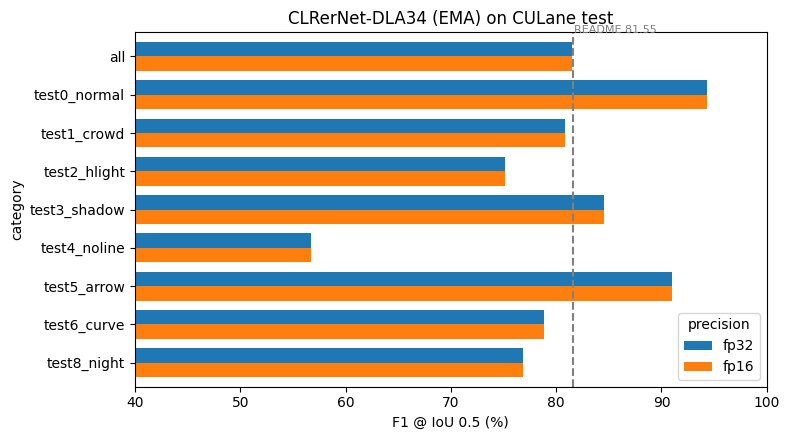

In [10]:
rows = []
for tag, res in ACC.items():
    for (thr, name), v in res.items():
        rows.append(dict(precision=tag, iou=thr, category=name, **v))
ACC_DF = pd.DataFrame(rows)
ACC_DF.to_csv(os.path.join(RESULTS_DIR, "accuracy_culane.csv"), index=False)

overall = ACC_DF[ACC_DF.category == "all"].pivot_table(index="iou", columns="precision", values=["F1", "Precision", "Recall"])
print("Overall (all categories):"); display((overall * 100).round(2))
percat = ACC_DF[ACC_DF.iou == 0.5].pivot_table(index="category", columns="precision", values="F1", sort=False) * 100
fp_cross = ACC_DF[(ACC_DF.iou == 0.5) & (ACC_DF.category == "test7_cross")].set_index("precision")["FP"]
percat = percat.drop(index="test7_cross", errors="ignore")
print("F1@0.5 per category (%):"); display(percat.round(2))
print("test7_cross false positives (no GT lanes in this category):", fp_cross.to_dict())

ax = percat.plot.barh(figsize=(8, 4.5), width=0.75)
ax.axvline(81.55, ls="--", c="gray"); ax.text(81.7, -0.6, "README 81.55", color="gray", fontsize=8)
ax.set_xlabel("F1 @ IoU 0.5 (%)"); ax.set_xlim(40, 100); ax.invert_yaxis(); ax.set_title("CLRerNet-DLA34 (EMA) on CULane test")
plt.tight_layout(); plt.savefig(os.path.join(RESULTS_DIR, "accuracy_per_category.png"), dpi=150); plt.show()

## 4. Latency on the NVIDIA GPU
* **Network latency** (batch 1, the real-time case): CUDA-event timed forward pass, FP32 and FP16 (autocast), eager vs **CUDA Graph** (one graph launch instead of ~300 kernel launches — shows how much of batch-1 latency is CPU launch overhead, which matters even more on the Jetson's slower CPU; TensorRT removes most of it too).
* **End-to-end per-frame pipeline**: JPEG decode → crop/resize/normalise → H2D → network → D2H → decode (softmax, threshold, lane NMS, lane build). CULane-txt writing is shown separately (only needed for evaluation).
* **Throughput vs batch size**.

In [11]:
import torch.nn.functional as F

def stats(ms):
    ms = np.asarray(ms, dtype=np.float64)
    return dict(mean_ms=ms.mean(), median_ms=np.median(ms), p90_ms=np.percentile(ms, 90),
                p99_ms=np.percentile(ms, 99), min_ms=ms.min(), std_ms=ms.std(), fps=1000.0 / ms.mean())

def cuda_timeit(fn, iters=LAT_ITERS, warmup=LAT_WARMUP):
    for _ in range(warmup):
        fn()
    torch.cuda.synchronize()
    ts = []
    for _ in range(iters):
        s, e = torch.cuda.Event(enable_timing=True), torch.cuda.Event(enable_timing=True)
        s.record(); fn(); e.record(); e.synchronize()
        ts.append(s.elapsed_time(e))
    return np.array(ts)

def eager_runner(model, x, amp):
    def run():
        with torch.inference_mode(), torch.autocast("cuda", dtype=torch.float16, enabled=amp):
            return model(x)
    return run

def cuda_graph_runner(model, x, amp):
    static_x = x.clone()
    s = torch.cuda.Stream(); s.wait_stream(torch.cuda.current_stream())
    with torch.cuda.stream(s), torch.no_grad(), torch.autocast("cuda", dtype=torch.float16, enabled=amp, cache_enabled=False):
        for _ in range(5):
            model(static_x)
    torch.cuda.current_stream().wait_stream(s)
    g = torch.cuda.CUDAGraph()
    with torch.cuda.graph(g), torch.no_grad(), torch.autocast("cuda", dtype=torch.float16, enabled=amp, cache_enabled=False):
        static_out = model(static_x)
    def run(new_x=None):
        if new_x is not None:
            static_x.copy_(new_x)
        g.replay()
        return static_out
    return run

# a real preprocessed frame as input
_img0 = cv2.imread(os.path.join(LOCAL_DATA, EVAL_LIST[0]))
X1 = torch.from_numpy(preprocess_bgr(_img0))[None].to(DEVICE)

LAT = OrderedDict()
assert DEVICE == "cuda", "latency section needs a GPU runtime"
for amp in (False, True):
    tag = "fp16" if amp else "fp32"
    LAT[f"{tag} eager"] = stats(cuda_timeit(eager_runner(model, X1, amp)))
    try:
        LAT[f"{tag} CUDA graph"] = stats(cuda_timeit(cuda_graph_runner(model, X1, amp)))
    except Exception as ex:
        print(f"CUDA graph capture failed ({tag}):", repr(ex)[:200])
LAT_DF = pd.DataFrame(LAT).T
print(f"Network latency, batch 1, input 1x3x320x800, {ENV['gpu']}")
display(LAT_DF.round(3))

# check: CUDA graph output == eager output
with torch.inference_mode():
    ref = model(X1)
g_out = cuda_graph_runner(model, X1, False)()
print("max |eager - graph| on xs:", (ref[3] - g_out[3]).abs().max().item())

Network latency, batch 1, input 1x3x320x800, Tesla T4


,mean_ms,median_ms,p90_ms,p99_ms,min_ms,std_ms,fps
fp32 eager,19.559,19.546,19.928,20.353,18.563,0.375,51.128
fp32 CUDA graph,19.980,20.013,20.345,20.513,19.044,0.324,50.049
fp16 eager,14.107,13.693,14.914,20.696,13.074,1.395,70.885
fp16 CUDA graph,7.440,7.464,7.496,7.584,7.336,0.060,134.409


max |eager - graph| on xs: 0.0


,imread (JPEG decode),preprocess,H2D copy,network (GPU),D2H copy,decode (NMS + lanes),CULane txt (eval only),total w/o eval txt,FPS w/o eval txt
"fp32, CPU preprocess",9.233,1.837,0.696,17.049,0.192,0.423,0.841,29.429,33.980
"fp16, CPU preprocess",8.804,1.812,0.684,14.894,0.181,0.404,0.821,26.779,37.343
"fp16, GPU preprocess",8.781,0.199,0.639,14.837,0.183,0.407,0.821,25.047,39.925


mean |cv2 - GPU preprocess| = 0.0007858987664803863


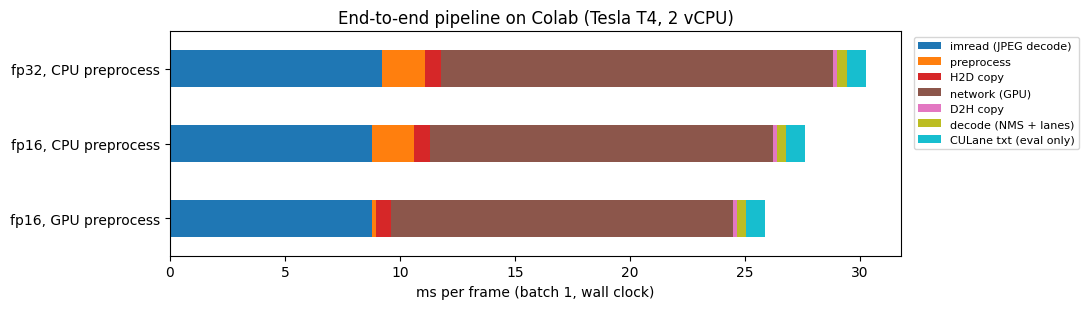

In [12]:
# ---------------- end-to-end per-frame pipeline (batch 1), wall-clock per stage ----------------
def preprocess_gpu(img_u8_gpu):
    # GPU alternative to cv2 preprocessing: uint8 HWC frame -> crop -> float -> bilinear resize
    x = img_u8_gpu[270:590].permute(2, 0, 1).unsqueeze(0).float().div_(255.0)
    return F.interpolate(x, size=(320, 800), mode="bilinear", align_corners=False, antialias=False)

def pipeline_breakdown(n=200, amp=False, gpu_pre=False):
    rels = EVAL_LIST[: n]
    pin = torch.empty((1, 3, 320, 800), dtype=torch.float32).pin_memory()
    pin_u8 = torch.empty((590, 1640, 3), dtype=torch.uint8).pin_memory()
    xin = torch.empty((1, 3, 320, 800), device=DEVICE)
    rec = defaultdict(list)
    sync = torch.cuda.synchronize
    with torch.inference_mode(), torch.autocast("cuda", dtype=torch.float16, enabled=amp):
        for i, rel in enumerate(rels):
            t0 = time.perf_counter()
            img = cv2.imread(os.path.join(LOCAL_DATA, rel))
            t1 = time.perf_counter()
            if gpu_pre:
                pin_u8.copy_(torch.from_numpy(img)); g = pin_u8.to(DEVICE, non_blocking=True); sync()
                t2 = time.perf_counter()
                xin = preprocess_gpu(g); sync()
                t3 = time.perf_counter()
                rec["H2D copy"].append(t2 - t1); rec["preprocess"].append(t3 - t2)
            else:
                x = preprocess_bgr(img)
                t2 = time.perf_counter()
                pin.copy_(torch.from_numpy(x)[None]); xin.copy_(pin, non_blocking=True); sync()
                t3 = time.perf_counter()
                rec["preprocess"].append(t2 - t1); rec["H2D copy"].append(t3 - t2)
            outs = model(xin); sync()
            t4 = time.perf_counter()
            cls, ap, ln, xs = [o[0].float().cpu().numpy() for o in outs]
            t5 = time.perf_counter()
            lanes, _ = decode_one(cls, ap, ln, xs)
            t6 = time.perf_counter()
            _ = lanes_to_culane_string(lanes)
            t7 = time.perf_counter()
            rec["imread (JPEG decode)"].append(t1 - t0); rec["network (GPU)"].append(t4 - t3)
            rec["D2H copy"].append(t5 - t4); rec["decode (NMS + lanes)"].append(t6 - t5)
            rec["CULane txt (eval only)"].append(t7 - t6)
    order = ["imread (JPEG decode)", "preprocess", "H2D copy", "network (GPU)", "D2H copy",
             "decode (NMS + lanes)", "CULane txt (eval only)"]
    skip = 10   # warm-up frames
    return OrderedDict((k, np.mean(rec[k][skip:]) * 1e3) for k in order)

# warm-up cudnn for this path
for _ in range(20):
    eager_runner(model, X1, False)(); eager_runner(model, X1, True)()

PIPE = OrderedDict()
PIPE["fp32, CPU preprocess"] = pipeline_breakdown(amp=False)
PIPE["fp16, CPU preprocess"] = pipeline_breakdown(amp=True)
PIPE["fp16, GPU preprocess"] = pipeline_breakdown(amp=True, gpu_pre=True)
PIPE_DF = pd.DataFrame(PIPE).T
PIPE_DF["total w/o eval txt"] = PIPE_DF.drop(columns=["CULane txt (eval only)"]).sum(axis=1)
PIPE_DF["FPS w/o eval txt"] = 1000 / PIPE_DF["total w/o eval txt"]
display(PIPE_DF.round(3))

# numerical difference between CPU (cv2) and GPU preprocessing
g = preprocess_gpu(torch.from_numpy(_img0).to(DEVICE))
print("mean |cv2 - GPU preprocess| =", (g.cpu() - torch.from_numpy(preprocess_bgr(_img0))[None]).abs().mean().item())

ax = PIPE_DF.drop(columns=["total w/o eval txt", "FPS w/o eval txt"]).plot.barh(stacked=True, figsize=(11, 3.2), colormap="tab10")
ax.set_xlabel("ms per frame (batch 1, wall clock)"); ax.set_title(f"End-to-end pipeline on Colab ({ENV['gpu']}, {os.cpu_count()} vCPU)")
ax.legend(bbox_to_anchor=(1.01, 1), loc="upper left", fontsize=8); ax.invert_yaxis()
plt.tight_layout(); plt.savefig(os.path.join(RESULTS_DIR, "pipeline_breakdown.png"), dpi=150); plt.show()

ms_per_batch        images_per_s       peak_mem_MB         
precision         fp16   fp32         fp16  fp32        fp16     fp32
batch                                                                
1                 14.1   20.1         70.8  49.6       148.7    165.1
2                 14.3   38.6        139.7  51.8       225.0   2234.0
4                 25.2   76.2        158.4  52.5       335.8   4052.2
8                 47.3  131.6        169.2  60.8       556.1   7692.3
16                91.4  203.9        175.1  78.5       998.5  10051.2
32               181.9  413.9        175.9  77.3      1207.9   1707.9

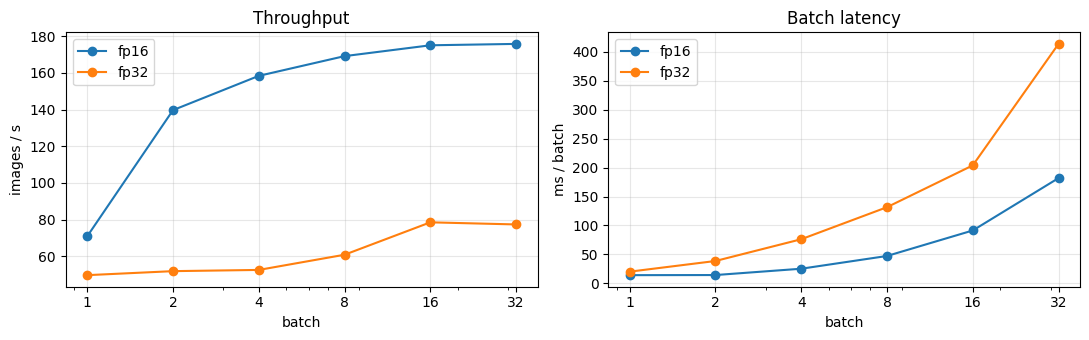

weights: 60.4 MB fp32 (30.2 MB fp16), buffers: 0.06 MB


In [13]:
# ---------------- throughput vs batch size + peak memory ----------------
TPUT = []
for bs in (1, 2, 4, 8, 16, 32):
    xb = X1.repeat(bs, 1, 1, 1)
    for amp in (False, True):
        torch.cuda.empty_cache(); torch.cuda.reset_peak_memory_stats()
        ms = cuda_timeit(eager_runner(model, xb, amp), iters=max(30, LAT_ITERS // bs), warmup=10)
        TPUT.append(dict(batch=bs, precision="fp16" if amp else "fp32", ms_per_batch=ms.mean(),
                         ms_per_image=ms.mean() / bs, images_per_s=bs * 1000 / ms.mean(),
                         peak_mem_MB=torch.cuda.max_memory_allocated() / 2**20))
TPUT_DF = pd.DataFrame(TPUT)
display(TPUT_DF.pivot(index="batch", columns="precision", values=["ms_per_batch", "images_per_s", "peak_mem_MB"]).round(1))
fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
for prec, d in TPUT_DF.groupby("precision"):
    ax[0].plot(d.batch, d.images_per_s, "o-", label=prec); ax[1].plot(d.batch, d.ms_per_batch, "o-", label=prec)
ax[0].set(xscale="log", xlabel="batch", ylabel="images / s", title="Throughput"); ax[0].set_xticks([1, 2, 4, 8, 16, 32], [1, 2, 4, 8, 16, 32])
ax[1].set(xscale="log", xlabel="batch", ylabel="ms / batch", title="Batch latency"); ax[1].set_xticks([1, 2, 4, 8, 16, 32], [1, 2, 4, 8, 16, 32])
for a in ax: a.legend(); a.grid(alpha=.3)
plt.tight_layout(); plt.savefig(os.path.join(RESULTS_DIR, "throughput_vs_batch.png"), dpi=150); plt.show()

weights_MB = sum(p.numel() * p.element_size() for p in model.parameters()) / 2**20
buffers_MB = sum(b.numel() * b.element_size() for b in model.buffers()) / 2**20
print(f"weights: {weights_MB:.1f} MB fp32 ({weights_MB/2:.1f} MB fp16), buffers: {buffers_MB:.2f} MB")

## 5. Runtime of each part of the model (where does the time go?)
Every block of the forward pass is wrapped in a named section (see `SECTION(...)` in the model code):

```
backbone/  base_layer (7x7 conv @320x800) · level0 (@320x800) · level1 (@160x400) · level2 (@80x200) · level3 (@40x100) · level4 (@20x50) · level5 (@10x25)
neck/      lateral_1x1 · top_down (nearest upsample + add) · fpn_3x3
head/      anchor_init · stage{0,1,2}/ roi_pool(grid_sample) · roi_conv_fc (9x1 convs + FC + LayerNorm) · cross_attention · cls_reg_fc · anchor_decode
```
Section times are measured with CUDA events on the GPU stream, so they include GPU idle gaps caused by kernel-launch overhead – exactly what the latency of that part is at batch 1. The `torch.profiler` cell below then shows pure kernel time, the kernel-type mix and how busy the GPU actually is.

In [14]:
def section_profile(model, x, amp=False, iters=200, warmup=30):
    SECTION.reset()
    with torch.inference_mode(), torch.autocast("cuda", dtype=torch.float16, enabled=amp):
        for _ in range(warmup):
            model(x)
        torch.cuda.synchronize()
        SECTION.enabled = True
        try:
            for i in range(iters):
                model(x)
                if i % 50 == 49:
                    SECTION.collect()
        finally:
            SECTION.enabled = False
    SECTION.collect()
    rows = []
    for name, ts in SECTION.times.items():
        ts = np.asarray(ts)
        calls = len(ts) / iters
        rows.append(dict(section=name, depth=name.count("/"), order=SECTION.order[name],
                         ms=ts.mean() * calls, median_ms=np.median(ts) * calls, std_ms=ts.std()))
    df = pd.DataFrame(rows).sort_values("order").reset_index(drop=True)
    total = df[df.depth == 0].ms.sum()
    df["share_%"] = 100 * df.ms / total
    names = set(df.section)
    df["is_leaf"] = [not any(n2.startswith(n + "/") for n2 in names) for n in df.section]
    df["part"] = df.section.str.split("/").str[0]
    return df, total

SEC = {}
for amp in (False, True):
    tag = "fp16" if amp else "fp32"
    SEC[tag], tot = section_profile(model, X1, amp)
    print(f"[{tag}] sum of top-level sections = {tot:.3f} ms  (plain eager forward: {LAT[tag + ' eager']['mean_ms']:.3f} ms)")

show = SEC["fp32"][["section", "depth"]].copy()
show["section"] = [("    " * d) + s.split("/")[-1] for s, d in zip(show.section, show.depth)]
for tag in SEC:
    show[f"{tag} ms"] = SEC[tag].ms.values
    show[f"{tag} %"] = SEC[tag]["share_%"].values
display(show.drop(columns="depth").round(3).style.hide(axis="index").bar(subset=["fp32 %"], color="#f4a582", vmin=0, vmax=100))
SEC["fp32"].assign(**{f"fp16_ms": SEC["fp16"].ms.values}).to_csv(os.path.join(RESULTS_DIR, "section_times.csv"), index=False)

[fp32] sum of top-level sections = 20.988 ms  (plain eager forward: 19.559 ms)
[fp16] sum of top-level sections = 16.348 ms  (plain eager forward: 14.107 ms)


section,fp32 ms,fp32 %,fp16 ms,fp16 %
backbone,17.535000,83.545000,6.585000,40.278000
base_layer,1.503000,7.160000,0.703000,4.300000
level0,1.437000,6.847000,0.558000,3.412000
level1,0.448000,2.134000,0.278000,1.703000
level2,2.706000,12.894000,0.656000,4.013000
level3,4.378000,20.861000,1.403000,8.581000
level4,4.460000,21.250000,1.795000,10.978000
level5,2.584000,12.313000,1.063000,6.502000
neck,0.431000,2.054000,1.007000,6.161000
lateral_1x1,0.088000,0.419000,0.355000,2.172000


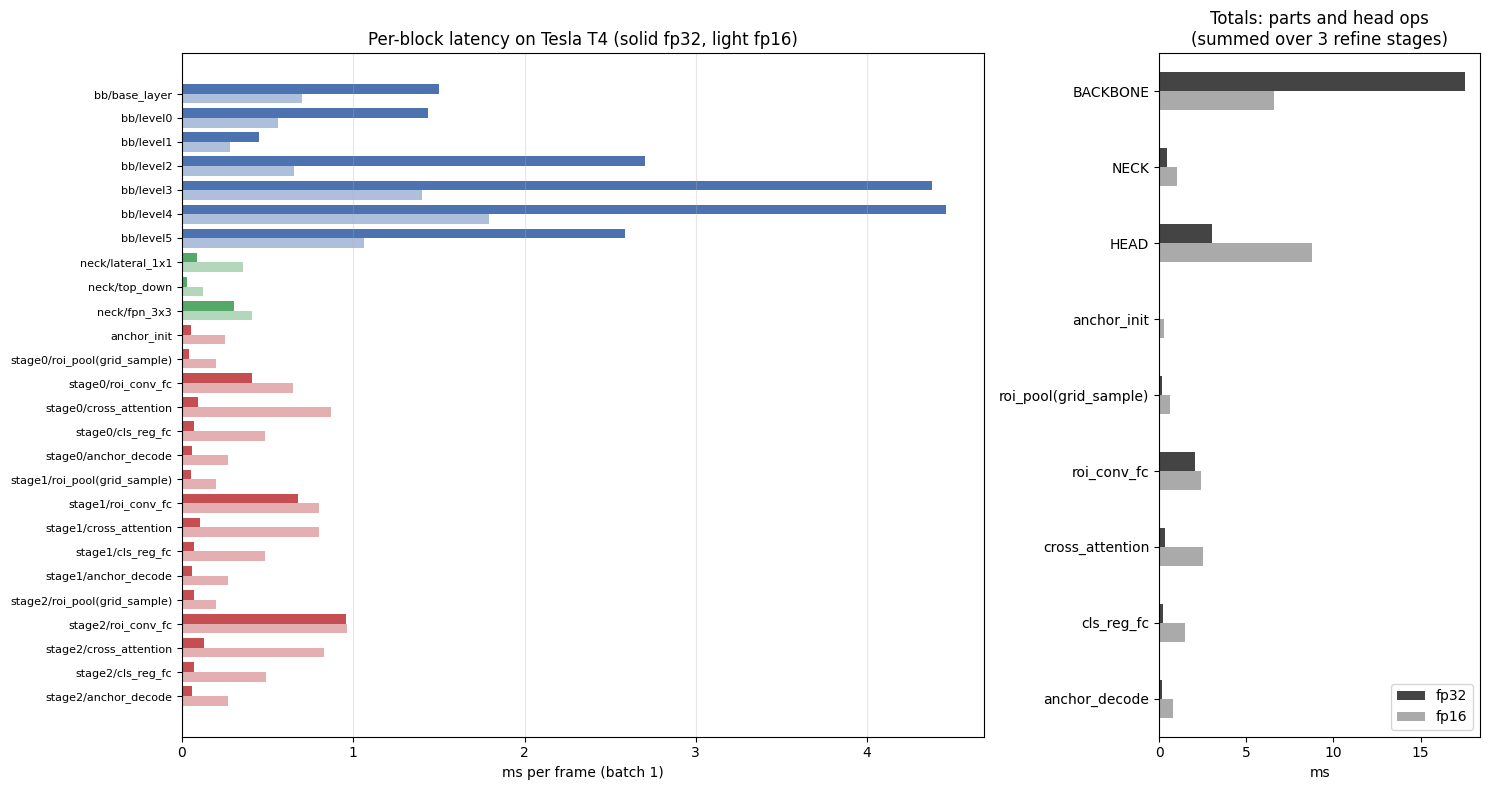

,fp32,fp16
BACKBONE,17.535,6.585
NECK,0.431,1.007
HEAD,3.022,8.756
anchor_init,0.051,0.252
roi_pool(grid_sample),0.162,0.595
roi_conv_fc,2.045,2.413
cross_attention,0.326,2.503
cls_reg_fc,0.212,1.459
anchor_decode,0.176,0.809


In [15]:
PART_COLORS = {"backbone": "#4C72B0", "neck": "#55A868", "head": "#C44E52"}
fig, axes = plt.subplots(1, 2, figsize=(15, 8), gridspec_kw=dict(width_ratios=[3, 1.2]))
leaf = SEC["fp32"][SEC["fp32"].is_leaf].copy()
leaf16 = SEC["fp16"].set_index("section").loc[leaf.section]
y = np.arange(len(leaf))
axes[0].barh(y - 0.2, leaf.ms, 0.4, color=[PART_COLORS[p] for p in leaf.part], label="fp32")
axes[0].barh(y + 0.2, leaf16.ms.values, 0.4, color=[PART_COLORS[p] for p in leaf.part], alpha=0.45, label="fp16")
axes[0].set_yticks(y, [s.replace("backbone/", "bb/").replace("head/", "") for s in leaf.section], fontsize=8)
axes[0].invert_yaxis(); axes[0].set_xlabel("ms per frame (batch 1)"); axes[0].grid(axis="x", alpha=.3)
axes[0].set_title(f"Per-block latency on {ENV['gpu']} (solid fp32, light fp16)")
# head aggregated by operation type across the 3 refine stages
agg = []
for tag in ("fp32", "fp16"):
    d = SEC[tag]
    top = d[d.depth == 0].set_index("section").ms
    hd = d[(d.part == "head") & d.is_leaf].copy()
    hd["op"] = hd.section.str.split("/").str[-1]
    a = hd.groupby("op", sort=False).ms.sum()
    agg.append(pd.concat([top.rename(lambda s: s.upper()), a]).rename(tag))
AGG = pd.concat(agg, axis=1)
AGG.plot.barh(ax=axes[1], color=["#444", "#aaa"]); axes[1].invert_yaxis()
axes[1].set_title("Totals: parts and head ops\n(summed over 3 refine stages)"); axes[1].set_xlabel("ms")
plt.tight_layout(); plt.savefig(os.path.join(RESULTS_DIR, "section_times.png"), dpi=150); plt.show()
display(AGG.round(3))

[fp32] wall 27.63 ms/iter (profiler on) | GPU kernel time 27.73 ms | GPU busy 100% | 559 kernel launches / frame
[fp16] wall 32.69 ms/iter (profiler on) | GPU kernel time 9.73 ms | GPU busy 30% | 631 kernel launches / frame


,fp32,fp16,fp32 %
category,,,
gemm / matmul,21.442,3.682,77.3
convolution,2.041,2.423,7.4
batchnorm,1.607,1.412,5.8
elementwise (relu/add/...),1.189,0.863,4.3
other,0.800,0.000,2.9
cat / copy / cast,0.409,1.124,1.5
max-pool,0.185,0.166,0.7
upsample / resize,0.029,0.030,0.1
layernorm,0.020,0.021,0.1


Top-15 kernels (fp32):


,kernel,ms_per_iter,launches_per_iter,category
10,"void implicit_convolve_sgemm<float, float, int...",9.8807,16.0,gemm / matmul
3,"void implicit_convolve_sgemm<float, float, int...",8.8239,12.0,gemm / matmul
4,"void cudnn::bn_fw_inf_1C11_kernel_NCHW<float, ...",1.6066,49.0,batchnorm
30,volta_gcgemm_64x32_nt,1.2773,18.0,gemm / matmul
28,"void fft1d_r2c_32<float, float, float2, false,...",0.8887,18.0,convolution
7,volta_sgemm_128x64_nn,0.8426,12.0,gemm / matmul
5,void at::native::vectorized_elementwise_kernel...,0.7133,63.0,elementwise (relu/add/...)
31,"void fft1d_c2r_32<float2, float, float, false,...",0.6543,18.0,convolution
2,cudaEventRecordWithFlags,0.3950,64.0,other
0,cudaStreamIsCapturing,0.3723,96.0,other


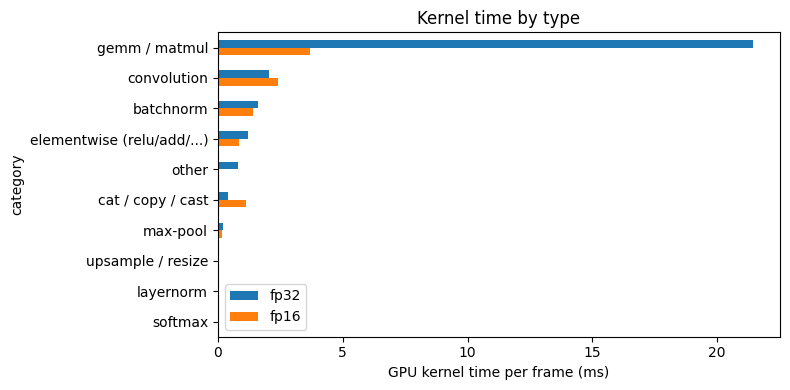

Chrome traces saved to /content/drive/MyDrive/clrernet_profiling - open in https://ui.perfetto.dev or chrome://tracing


In [16]:
# ---------------- torch.profiler: kernel-level view ----------------
from torch.profiler import profile, ProfilerActivity

def kernel_category(name):
    n = name.lower()
    rules = [("batchnorm", ("batch_norm", "bn_fw", "batchnorm")), ("grid_sample", ("grid_sampler",)),
             ("layernorm", ("layer_norm",)), ("softmax", ("softmax",)), ("gemm / matmul", ("gemm", "gemv")),
             ("convolution", ("conv", "winograd", "implicit", "fprop", "xmma", "cudnn", "fft")),
             ("max-pool", ("pool",)), ("upsample / resize", ("upsample", "interpolate", "nearest")),
             ("cat / copy / cast", ("cat", "copy", "memcpy", "memset", "to_copy")),
             ("elementwise (relu/add/...)", ("elementwise", "vectorized", "unrolled", "reduce", "launch_kernel"))]
    for cat, keys in rules:
        if any(k in n for k in keys):
            return cat
    return "other"

def dev_attr(e, self_=True):
    for a in (("self_device_time_total", "self_cuda_time_total") if self_ else ("device_time_total", "cuda_time_total")):
        if hasattr(e, a):
            return getattr(e, a)
    return 0.0

PROF = {}
N_PROF = 20
for amp in (False, True):
    tag = "fp16" if amp else "fp32"
    SECTION.enabled, SECTION.use_record_function = True, True
    try:
        with torch.inference_mode(), torch.autocast("cuda", dtype=torch.float16, enabled=amp):
            for _ in range(10):
                model(X1)
            torch.cuda.synchronize()
            with profile(activities=[ProfilerActivity.CPU, ProfilerActivity.CUDA], record_shapes=False) as prof:
                t0 = time.perf_counter()
                for _ in range(N_PROF):
                    model(X1)
                torch.cuda.synchronize()
                wall_ms = (time.perf_counter() - t0) * 1e3 / N_PROF
    finally:
        SECTION.enabled, SECTION.use_record_function = False, False
        SECTION.reset()
    prof.export_chrome_trace(os.path.join(RESULTS_DIR, f"torch_profiler_trace_{tag}.json"))
    ka = prof.key_averages()
    kern = [(e.key, dev_attr(e) / 1e3 / N_PROF, e.count / N_PROF) for e in ka
            if dev_attr(e) > 0 and not e.key.startswith(("backbone", "neck", "head", "aten::", "ProfilerStep"))]
    kdf = pd.DataFrame(kern, columns=["kernel", "ms_per_iter", "launches_per_iter"]).sort_values("ms_per_iter", ascending=False)
    kdf["category"] = kdf.kernel.map(kernel_category)
    PROF[tag] = dict(kernels=kdf, wall_ms=wall_ms, kernel_ms=kdf.ms_per_iter.sum(), launches=kdf.launches_per_iter.sum())
    print(f"[{tag}] wall {wall_ms:.2f} ms/iter (profiler on) | GPU kernel time {PROF[tag]['kernel_ms']:.2f} ms "
          f"| GPU busy {100*PROF[tag]['kernel_ms']/wall_ms:.0f}% | {PROF[tag]['launches']:.0f} kernel launches / frame")

CAT_DF = pd.concat({t: PROF[t]["kernels"].groupby("category").ms_per_iter.sum() for t in PROF}, axis=1).fillna(0)
CAT_DF = CAT_DF.sort_values("fp32", ascending=False)
display((CAT_DF).round(3).assign(**{"fp32 %": (100 * CAT_DF.fp32 / CAT_DF.fp32.sum()).round(1)}))
print("Top-15 kernels (fp32):")
display(PROF["fp32"]["kernels"].head(15).assign(kernel=lambda d: d.kernel.str.slice(0, 90)).round(4))
CAT_DF.plot.barh(figsize=(8, 4)).invert_yaxis(); plt.xlabel("GPU kernel time per frame (ms)"); plt.title("Kernel time by type")
plt.tight_layout(); plt.savefig(os.path.join(RESULTS_DIR, "kernel_categories.png"), dpi=150); plt.show()
print("Chrome traces saved to", RESULTS_DIR, "- open in https://ui.perfetto.dev or chrome://tracing")

## 6. Parameters, FLOPs, memory access, roofline
* **FLOPs** are counted on the real forward pass with a `TorchDispatchMode` that sees every ATen op (using PyTorch's own `flop_registry` formulas: conv / matmul / addmm / bmm; 1 MAC = 2 FLOPs). The README's "18.4 GFLOPs" follows the common convention of reporting MACs.
* **Memory access** is estimated two ways:
  1. *unfused (eager PyTorch)*: bytes read + written by every ATen op (views are free) – roughly what eager PyTorch moves through DRAM/L2;
  2. *fused (TensorRT-like)*: per Conv/Linear layer = input + weights + output only (BN, ReLU, residual add fused into the conv) – a lower bound closer to what TensorRT on the Jetson moves.
* **Arithmetic intensity** (FLOPs/byte) per layer vs. each device's ridge point tells you if a layer is compute- or memory-bound. Orin Nano has ~3–5× less bandwidth than a T4, so memory-bound layers (the high-resolution stem, BN/ReLU/add traffic, grid-sample and small FCs) get relatively more expensive there.

In [17]:
from torch.utils._python_dispatch import TorchDispatchMode
from torch.utils._pytree import tree_flatten
from torch.utils.flop_counter import FlopCounterMode
try:
    from torch.utils.flop_counter import flop_registry as FLOP_REGISTRY
except Exception:
    FLOP_REGISTRY = {}

VIEW_OPS = {"view", "_unsafe_view", "reshape", "_reshape_alias", "permute", "expand", "t", "transpose", "unsqueeze",
            "squeeze", "select", "slice", "alias", "detach", "as_strided", "flatten", "unflatten", "split",
            "split_with_sizes", "chunk", "unbind", "narrow", "view_as", "lift_fresh", "empty", "empty_like",
            "empty_strided", "_to_copy_view", "expand_as", "numpy_T", "_local_scalar_dense"}

def _nbytes(objs):
    return sum(t.numel() * t.element_size() for t in tree_flatten(objs)[0] if isinstance(t, torch.Tensor))

class OpCounter(TorchDispatchMode):
    def __init__(self):
        super().__init__()
        self.rows = []
    def __torch_dispatch__(self, func, types, args=(), kwargs=None):
        kwargs = kwargs or {}
        out = func(*args, **kwargs)
        pkt = func._overloadpacket
        name = pkt.__name__
        flops = 0
        if pkt in FLOP_REGISTRY:
            try:
                flops = int(FLOP_REGISTRY[pkt](*args, **kwargs, out_val=out))
            except Exception:
                flops = 0
        b_in = b_out = 0
        if name not in VIEW_OPS:
            b_in, b_out = _nbytes((args, kwargs)), _nbytes(out)
        self.rows.append(dict(section=SECTION.current or "(top)", op=name, flops=flops, bytes_in=b_in, bytes_out=b_out))
        return out

def count_ops(model, x, amp=False):
    SECTION.reset(); SECTION.enabled = True
    try:
        with torch.inference_mode(), torch.autocast("cuda", dtype=torch.float16, enabled=amp and DEVICE == "cuda"):
            with OpCounter() as oc:
                model(x)
    finally:
        SECTION.enabled = False; SECTION.reset()
    return pd.DataFrame(oc.rows)

OPS = {"fp32": count_ops(model, X1, False), "fp16": count_ops(model, X1, True)}
with torch.inference_mode(), FlopCounterMode(display=False) as fcm:
    model(X1)
total_flops = fcm.get_total_flops()
print(f"FlopCounterMode total: {total_flops/1e9:.2f} GFLOPs = {total_flops/2e9:.2f} GMACs   "
      f"(dispatch counter: {OPS['fp32'].flops.sum()/1e9:.2f} GFLOPs)  |  README: 18.4 'GFLOPs' (=MACs convention)")

# parameters per part
PARAM_GROUPS = [("backbone/base_layer", ("backbone.model.base_layer",))] + \
    [(f"backbone/level{i}", (f"backbone.model.level{i}",)) for i in range(6)] + [
    ("neck/lateral_1x1", ("neck.lateral_convs",)), ("neck/fpn_3x3", ("neck.fpn_convs",)),
    ("head/anchor_embeddings (192x3)", ("bbox_head.anchor_generator",)),
    ("head/roi_gather 9x1 convs", ("bbox_head.attention.convs", "bbox_head.attention.catconv")),
    ("head/roi_gather fc + LayerNorm", ("bbox_head.attention.fc",)),
    ("head/cross_attention", ("bbox_head.attention.attention",)),
    ("head/cls_reg_fc", ("bbox_head.cls_modules", "bbox_head.reg_modules", "bbox_head.cls_layers", "bbox_head.reg_layers"))]
pcount = OrderedDict((g, 0) for g, _ in PARAM_GROUPS); pcount["other"] = 0
for n, p in model.named_parameters():
    g = next((g for g, prefs in PARAM_GROUPS if n.startswith(prefs)), "other")
    pcount[g] += p.numel()
PARAMS_DF = pd.DataFrame({"params": pcount}).query("params > 0")
PARAMS_DF["share_%"] = 100 * PARAMS_DF.params / PARAMS_DF.params.sum()
PARAMS_DF.loc["TOTAL"] = [PARAMS_DF.params.sum(), 100.0]
display(PARAMS_DF.assign(params_M=lambda d: d.params / 1e6).round(4))

FlopCounterMode total: 36.63 GFLOPs = 18.31 GMACs   (dispatch counter: 0.00 GFLOPs)  |  README: 18.4 'GFLOPs' (=MACs convention)


,params,share_%,params_M
backbone/base_layer,2384.0,0.0151,0.0024
backbone/level0,2336.0,0.0148,0.0023
backbone/level1,4672.0,0.0295,0.0047
backbone/level2,140032.0,0.8848,0.1400
backbone/level3,1207040.0,7.6269,1.2070
backbone/level4,4822528.0,30.4722,4.8225
backbone/level5,9050112.0,57.1850,9.0501
neck/lateral_1x1,57536.0,0.3636,0.0575
neck/fpn_3x3,110784.0,0.7000,0.1108
head/anchor_embeddings (192x3),576.0,0.0036,0.0006


In [18]:
# FLOPs + unfused memory traffic per section (fp32 and fp16 autocast)
def per_section(df):
    g = df.groupby("section", sort=False)[["flops", "bytes_in", "bytes_out"]].sum()
    g["bytes"] = g.bytes_in + g.bytes_out
    return g

S32, S16 = per_section(OPS["fp32"]), per_section(OPS["fp16"])
order = [s for s in SEC["fp32"].section if s in S32.index] + [s for s in S32.index if s not in set(SEC["fp32"].section)]
_leaf_ms = {t: SEC[t][SEC[t].is_leaf].set_index("section").ms for t in SEC}   # parents' time would double count
CPLX = pd.DataFrame({
    "GFLOPs": S32.flops.reindex(order) / 1e9,
    "MB moved fp32 (unfused)": S32.bytes.reindex(order) / 2**20,
    "MB moved fp16 (unfused)": S16.bytes.reindex(order).fillna(0) / 2**20,
    "ms fp32": _leaf_ms["fp32"].reindex(order),
    "ms fp16": _leaf_ms["fp16"].reindex(order)}).fillna(0)
CPLX["FLOP/byte fp32"] = (CPLX.GFLOPs * 1e9) / (CPLX["MB moved fp32 (unfused)"] * 2**20 + 1e-9)
CPLX["achieved GFLOP/s fp32"] = CPLX.GFLOPs / (CPLX["ms fp32"] / 1e3 + 1e-12)
CPLX["achieved GB/s fp32"] = CPLX["MB moved fp32 (unfused)"] * 2**20 / 1e9 / (CPLX["ms fp32"] / 1e3 + 1e-12)
tot = CPLX.sum(numeric_only=True)
print(f"TOTAL: {tot.GFLOPs:.2f} GFLOPs, unfused traffic {tot['MB moved fp32 (unfused)']:.0f} MB (fp32) / "
      f"{tot['MB moved fp16 (unfused)']:.0f} MB (fp16) per frame")
display(CPLX.round(3))
CPLX.to_csv(os.path.join(RESULTS_DIR, "complexity_per_section.csv"))

ops_top = OPS["fp32"].assign(bytes=lambda d: d.bytes_in + d.bytes_out).groupby("op")[["flops", "bytes"]].sum()
ops_top = ops_top.assign(GFLOPs=lambda d: d.flops / 1e9, MB=lambda d: d.bytes / 2**20).drop(columns=["flops", "bytes"])
print("Memory traffic by ATen op (fp32, unfused):")
display(ops_top.sort_values("MB", ascending=False).head(15).round(2))

TOTAL: 0.00 GFLOPs, unfused traffic 930 MB (fp32) / 587 MB (fp16) per frame


,GFLOPs,MB moved fp32 (unfused),MB moved fp16 (unfused),ms fp32,ms fp16,FLOP/byte fp32,achieved GFLOP/s fp32,achieved GB/s fp32
section,,,,,,,,
backbone/base_layer,0.0,81.064,44.940,1.503,0.703,0.0,0.0,56.567
backbone/level0,0.0,93.759,46.893,1.437,0.558,0.0,0.0,68.414
backbone/level1,0.0,54.706,27.379,0.448,0.278,0.0,0.0,128.098
backbone/level2,0.0,188.037,94.818,2.706,0.656,0.0,0.0,72.859
backbone/level3,0.0,192.115,102.959,4.378,1.403,0.0,0.0,46.009
backbone/level4,0.0,112.168,83.668,4.460,1.795,0.0,0.0,26.371
backbone/level5,0.0,58.717,81.132,2.584,1.063,0.0,0.0,23.824
neck/lateral_1x1,0.0,4.919,2.789,0.088,0.355,0.0,0.0,58.657
neck/top_down,0.0,5.188,2.594,0.031,0.122,0.0,0.0,176.850


Memory traffic by ATen op (fp32, unfused):


,GFLOPs,MB
op,,
conv2d,0.0,311.79
batch_norm,0.0,223.32
relu_,0.0,209.67
add,0.0,66.11
cat,0.0,65.80
max_pool2d,0.0,25.63
linear,0.0,8.72
grid_sampler,0.0,6.50
upsample_nearest2d,0.0,4.46


85 conv/linear layer calls, 18.29 GMACs, fused traffic 321 MB fp32 / 161 MB fp16
Roofline lower bound per part (fused, fp16, perfect overlap - real latency will be higher):


,layers,GMACs,MB_fp16_fused,ideal ms fp16 [T4],ideal ms fp16 [OrinNano super],ideal ms fp16 [OrinNano 15W],% mem-bound [T4],% mem-bound [OrinNano super],% mem-bound [OrinNano 15W]
part,,,,,,,,,
backbone/base_layer,1.0,0.602,9.282,0.030,0.095,0.143,100.000,100.000,100.000
backbone/level0,1.0,0.590,15.629,0.051,0.161,0.241,100.000,100.000,100.000
backbone/level1,1.0,0.295,11.728,0.038,0.121,0.181,100.000,100.000,100.000
backbone/level2,6.0,2.228,26.633,0.103,0.359,0.581,50.000,50.000,50.000
backbone/level3,11.0,4.817,27.688,0.167,0.613,1.023,36.364,27.273,27.273
backbone/level4,11.0,4.817,21.883,0.153,0.573,0.969,27.273,27.273,18.182
backbone/level5,6.0,2.261,20.668,0.073,0.271,0.455,50.000,33.333,16.667
neck/lateral_1x1,3.0,0.057,2.460,0.008,0.025,0.038,100.000,100.000,100.000
neck/fpn_3x3,3.0,0.194,1.493,0.006,0.023,0.039,33.333,33.333,33.333


,layer,section,type,in_shape,out_shape,params,MACs,bytes_fp16,AI_fp16
0,backbone.model.base_layer.0,backbone/base_layer,Conv2d,"(1, 3, 320, 800)","(1, 16, 320, 800)",2352,602112000,9732704,123.729644
1,backbone.model.level0.0,backbone/level0,Conv2d,"(1, 16, 320, 800)","(1, 16, 320, 800)",2304,589824000,16388608,71.979756
7,backbone.model.level2.tree2.conv2,backbone/level2,Conv2d,"(1, 64, 80, 200)","(1, 64, 80, 200)",36864,589824000,4169728,282.907662
6,backbone.model.level2.tree2.conv1,backbone/level2,Conv2d,"(1, 64, 80, 200)","(1, 64, 80, 200)",36864,589824000,4169728,282.907662
5,backbone.model.level2.tree1.conv2,backbone/level2,Conv2d,"(1, 64, 80, 200)","(1, 64, 80, 200)",36864,589824000,4169728,282.907662
18,backbone.model.level3.tree2.tree2.conv2,backbone/level3,Conv2d,"(1, 128, 40, 100)","(1, 128, 40, 100)",147456,589824000,2342912,503.496503
17,backbone.model.level3.tree2.tree2.conv1,backbone/level3,Conv2d,"(1, 128, 40, 100)","(1, 128, 40, 100)",147456,589824000,2342912,503.496503
15,backbone.model.level3.tree2.tree1.conv1,backbone/level3,Conv2d,"(1, 128, 40, 100)","(1, 128, 40, 100)",147456,589824000,2342912,503.496503
12,backbone.model.level3.tree1.tree2.conv1,backbone/level3,Conv2d,"(1, 128, 40, 100)","(1, 128, 40, 100)",147456,589824000,2342912,503.496503
11,backbone.model.level3.tree1.tree1.conv2,backbone/level3,Conv2d,"(1, 128, 40, 100)","(1, 128, 40, 100)",147456,589824000,2342912,503.496503


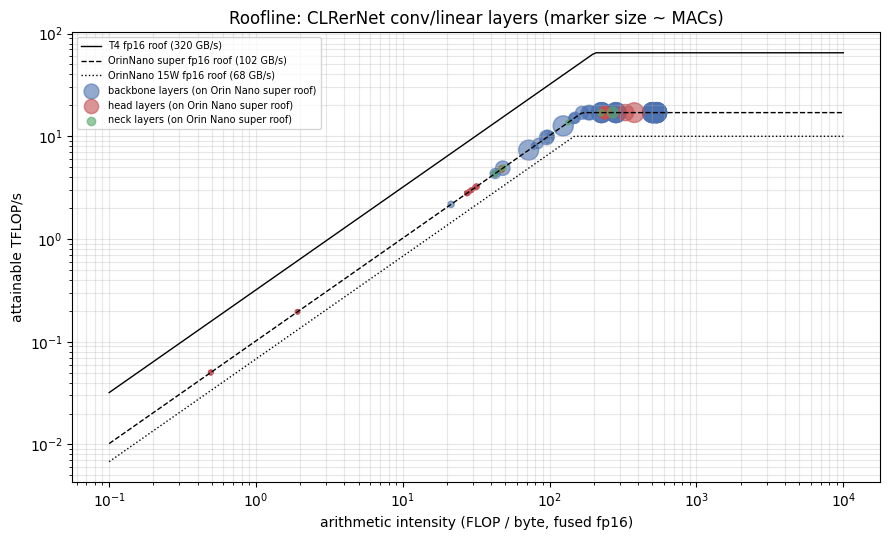

In [19]:
# ---------------- per-layer (Conv / Linear) table with a fused, TensorRT-like byte model ----------------
import torch.nn as nn
LAYER_ROWS = []
def _layer_hook(name):
    def hook(mod, inp, out):
        x = inp[0]
        if isinstance(mod, (nn.Conv2d, nn.Conv1d)):
            k = int(np.prod(mod.kernel_size)); macs = out.numel() * (mod.in_channels // mod.groups) * k
        else:
            macs = out.numel() * mod.in_features
        LAYER_ROWS.append(dict(layer=name, section=SECTION.current, type=type(mod).__name__,
                               in_shape=tuple(x.shape), out_shape=tuple(out.shape),
                               params=sum(p.numel() for p in mod.parameters(recurse=False)),
                               MACs=macs, act_in=x.numel(), act_out=out.numel()))
    return hook

hooks = [m.register_forward_hook(_layer_hook(n)) for n, m in model.named_modules() if isinstance(m, (nn.Conv2d, nn.Conv1d, nn.Linear))]
SECTION.reset(); SECTION.enabled = True
try:
    with torch.inference_mode():
        model(X1)
finally:
    SECTION.enabled = False; SECTION.reset()
    for h in hooks:
        h.remove()
LAYERS = pd.DataFrame(LAYER_ROWS)
for bpe, tag in ((4, "fp32"), (2, "fp16")):
    LAYERS[f"bytes_{tag}"] = (LAYERS.act_in + LAYERS.params + LAYERS.act_out) * bpe
    LAYERS[f"AI_{tag}"] = 2 * LAYERS.MACs / LAYERS[f"bytes_{tag}"]
print(f"{len(LAYERS)} conv/linear layer calls, {LAYERS.MACs.sum()/1e9:.2f} GMACs, "
      f"fused traffic {LAYERS.bytes_fp32.sum()/2**20:.0f} MB fp32 / {LAYERS.bytes_fp16.sum()/2**20:.0f} MB fp16")

# Device specs (edit if your Jetson runs a different power mode).
# T4: 8.1 TFLOPS FP32, 65 TFLOPS FP16 tensor core, 320 GB/s.
# Orin Nano 8GB: 1024 CUDA cores; FP32 = 1024*2*f_gpu; FP16 = NVIDIA-listed figure; LPDDR5 bandwidth.
DEVICES = {
    "T4":              dict(fp32=8.1e12,  fp16=65e12, bw=320e9, desc="Tesla T4 (Colab)"),
    "OrinNano super":  dict(fp32=2.09e12, fp16=17e12, bw=102e9, desc="Orin Nano 8GB, MAXN SUPER (JetPack 6.2), GPU 1020 MHz"),
    "OrinNano 15W":    dict(fp32=1.28e12, fp16=10e12, bw=68e9,  desc="Orin Nano 8GB, original 15 W mode, GPU 625 MHz"),
}
for dev, sp in DEVICES.items():
    for tag in ("fp32", "fp16"):
        LAYERS[f"t_{tag}_{dev}"] = np.maximum(2 * LAYERS.MACs / sp[tag], LAYERS[f"bytes_{tag}"] / sp["bw"]) * 1e3
        LAYERS[f"membound_{tag}_{dev}"] = LAYERS[f"AI_{tag}"] < sp[tag] / sp["bw"]

LAYERS["part"] = LAYERS.section.str.split("/").str[:2].str.join("/")
roof = LAYERS.groupby("part", sort=False).agg(
    layers=("layer", "count"), GMACs=("MACs", "sum"), MB_fp16_fused=("bytes_fp16", "sum"),
    **{f"ideal ms fp16 [{d}]": (f"t_fp16_{d}", "sum") for d in DEVICES},
    **{f"% mem-bound [{d}]": (f"membound_fp16_{d}", "mean") for d in DEVICES})
roof["GMACs"] /= 1e9; roof["MB_fp16_fused"] /= 2**20
for d in DEVICES:
    roof[f"% mem-bound [{d}]"] *= 100
roof.loc["TOTAL"] = roof.sum(numeric_only=True)
roof.loc["TOTAL", [f"% mem-bound [{d}]" for d in DEVICES]] = np.nan
print("Roofline lower bound per part (fused, fp16, perfect overlap - real latency will be higher):")
display(roof.round(3))
display(LAYERS[["layer", "section", "type", "in_shape", "out_shape", "params", "MACs", "bytes_fp16", "AI_fp16"]]
        .sort_values("MACs", ascending=False).head(15))
LAYERS.to_csv(os.path.join(RESULTS_DIR, "layers_roofline.csv"), index=False)

# roofline plot
fig, ax = plt.subplots(figsize=(9, 5.5))
ai = np.logspace(-1, 4, 200)
for (dev, sp), ls in zip(DEVICES.items(), ("-", "--", ":")):
    ax.plot(ai, np.minimum(sp["fp16"], ai * sp["bw"]) / 1e12, ls, c="k", lw=1, label=f"{dev} fp16 roof ({sp['bw']/1e9:.0f} GB/s)")
for part, d in LAYERS.groupby(LAYERS.section.str.split("/").str[0]):
    sp = DEVICES["OrinNano super"]
    ax.scatter(d.AI_fp16, np.minimum(sp["fp16"], d.AI_fp16 * sp["bw"]) / 1e12, s=10 + 200 * d.MACs / LAYERS.MACs.max(),
               alpha=.6, c=PART_COLORS.get(part, "gray"), label=f"{part} layers (on Orin Nano super roof)")
ax.set(xscale="log", yscale="log", xlabel="arithmetic intensity (FLOP / byte, fused fp16)", ylabel="attainable TFLOP/s",
       title="Roofline: CLRerNet conv/linear layers (marker size ~ MACs)")
ax.legend(fontsize=7); ax.grid(alpha=.3, which="both")
plt.tight_layout(); plt.savefig(os.path.join(RESULTS_DIR, "roofline.png"), dpi=150); plt.show()

In [20]:
# ---------------- peak GPU memory for batch-1 inference ----------------
MEM = {}
for amp in (False, True):
    tag = "fp16" if amp else "fp32"
    torch.cuda.synchronize(); torch.cuda.empty_cache(); torch.cuda.reset_peak_memory_stats()
    base = torch.cuda.memory_allocated()
    with torch.inference_mode(), torch.autocast("cuda", dtype=torch.float16, enabled=amp):
        _ = model(X1); torch.cuda.synchronize()
    MEM[tag] = dict(allocated_before_MB=base / 2**20, peak_MB=torch.cuda.max_memory_allocated() / 2**20,
                    activation_peak_MB=(torch.cuda.max_memory_allocated() - base) / 2**20)
MEM_DF = pd.DataFrame(MEM).T
display(MEM_DF.round(1))
# largest activations (per-block output sizes)
ACTS = []
def _act_hook(name):
    def h(m, i, o):
        outs = o if isinstance(o, (list, tuple)) else [o]
        ACTS.append(dict(block=name, shapes=[tuple(t.shape) for t in outs if torch.is_tensor(t)],
                         MB_fp32=sum(t.numel() * 4 for t in outs if torch.is_tensor(t)) / 2**20))
    return h
hs = [getattr(model.backbone.model, n).register_forward_hook(_act_hook("backbone." + n)) for n in
      ["base_layer", "level0", "level1", "level2", "level3", "level4", "level5"]] + [model.neck.register_forward_hook(_act_hook("neck (P3,P4,P5)"))]
with torch.inference_mode():
    model(X1)
for h in hs:
    h.remove()
ACTS_DF = pd.DataFrame(ACTS); display(ACTS_DF.round(2))

,allocated_before_MB,peak_MB,activation_peak_MB
fp32,204.2,252.4,48.2
fp16,204.3,236.3,31.9


,block,shapes,MB_fp32
0,backbone.base_layer,"[(1, 16, 320, 800)]",15.62
1,backbone.level0,"[(1, 16, 320, 800)]",15.62
2,backbone.level1,"[(1, 32, 160, 400)]",7.81
3,backbone.level2,"[(1, 64, 80, 200)]",3.91
4,backbone.level3,"[(1, 128, 40, 100)]",1.95
5,backbone.level4,"[(1, 256, 20, 50)]",0.98
6,backbone.level5,"[(1, 512, 10, 25)]",0.49
7,"neck (P3,P4,P5)","[(1, 64, 40, 100), (1, 64, 20, 50), (1, 64, 10...",1.28


## 7. Overall graph of the model
1. Layer-by-layer summary (`torchinfo`).
2. A **profiled block diagram**: every block annotated with output shape, params, GFLOPs and measured FP32/FP16 time on this GPU (colour = share of latency).
3. The exported ONNX graph (section 8) is the exact operator-level graph – open the `.onnx` saved in your Drive folder with [Netron](https://netron.app) to browse it.

In [21]:
try:
    from torchinfo import summary
    s = summary(model, input_data=X1, depth=4, col_names=("output_size", "num_params", "mult_adds"),
                row_settings=("var_names",), verbose=0, device=DEVICE)
    print(s)
    with open(os.path.join(RESULTS_DIR, "torchinfo_summary.txt"), "w") as f:
        f.write(str(s))
except Exception as ex:
    print("torchinfo failed:", repr(ex)[:300]); print(model)

Layer (type (var_name))                                      Output Shape              Param #                   Mult-Adds
CLRerNet (CLRerNet)                                          [1, 192, 2]               --                        --
├─DLANet (backbone)                                          [1, 64, 80, 200]          --                        --
│    └─DLA (model)                                           [1, 64, 80, 200]          --                        --
│    │    └─Sequential (base_layer)                          [1, 16, 320, 800]         --                        --
│    │    │    └─Conv2d (0)                                  [1, 16, 320, 800]         2,352                     602,112,000
│    │    │    └─BatchNorm2d (1)                             [1, 16, 320, 800]         32                        32
│    │    │    └─ReLU (2)                                    [1, 16, 320, 800]         --                        --
│    │    └─Sequential (level0)                         

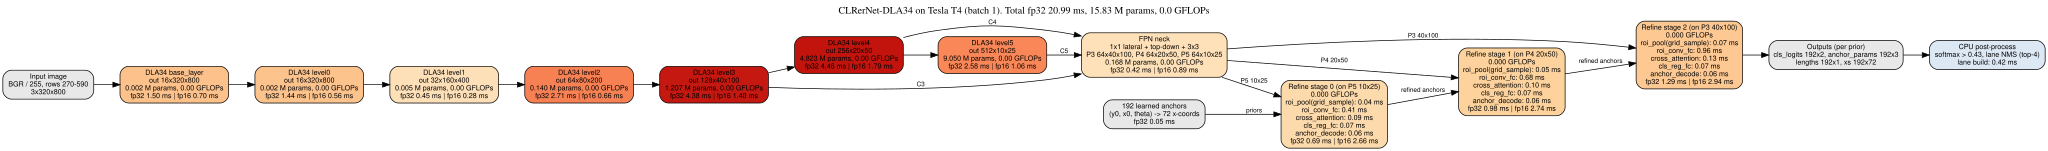

In [22]:
import matplotlib as mpl
def _ms(sec, tag):
    d = SEC[tag].set_index("section").ms
    return d.get(sec, np.nan)
def _gf(prefix):
    return CPLX[[i.startswith(prefix) for i in CPLX.index]].GFLOPs.sum()
def _pm(prefix):
    return sum(p.numel() for n, p in model.named_parameters() if n.startswith(prefix)) / 1e6
shape_of = {r.block.split(".")[-1]: r.shapes for r in ACTS_DF.itertuples()}
tot32 = SEC["fp32"][SEC["fp32"].depth == 0].ms.sum()
cmap = mpl.colormaps["OrRd"]
def color(ms):
    return mpl.colors.to_hex(cmap(0.1 + 0.85 * min(1.0, ms / (0.25 * tot32))))
def fmt_shape(s):
    return "x".join(map(str, s[0][1:])) if s else ""

dot = ["digraph CLRerNet {", 'rankdir=LR; node [shape=box, style="rounded,filled", fontname="Helvetica", fontsize=10];',
       'edge [fontname="Helvetica", fontsize=9];']
dot.append('input [label="Input image\\nBGR / 255, rows 270-590\\n3x320x800", fillcolor="#e8e8e8"];')
prev = "input"
for blk in ["base_layer", "level0", "level1", "level2", "level3", "level4", "level5"]:
    sec = f"backbone/{blk}"; m32, m16 = _ms(sec, "fp32"), _ms(sec, "fp16")
    lbl = (f"DLA34 {blk}\\nout {fmt_shape(shape_of.get(blk))}\\n{_pm('backbone.model.' + blk):.3f} M params, "
           f"{_gf(sec):.2f} GFLOPs\\nfp32 {m32:.2f} ms | fp16 {m16:.2f} ms")
    dot.append(f'{blk} [label="{lbl}", fillcolor="{color(m32)}"];')
    dot.append(f"{prev} -> {blk};"); prev = blk
neck32 = sum(_ms(f"neck/{s}", "fp32") for s in ["lateral_1x1", "top_down", "fpn_3x3"])
neck16 = sum(_ms(f"neck/{s}", "fp16") for s in ["lateral_1x1", "top_down", "fpn_3x3"])
dot.append(f'neck [label="FPN neck\\n1x1 lateral + top-down + 3x3\\nP3 64x40x100, P4 64x20x50, P5 64x10x25\\n'
           f'{_pm("neck"):.3f} M params, {_gf("neck"):.2f} GFLOPs\\nfp32 {neck32:.2f} ms | fp16 {neck16:.2f} ms", fillcolor="{color(neck32)}"];')
for c, blk in (("C3", "level3"), ("C4", "level4"), ("C5", "level5")):
    dot.append(f'{blk} -> neck [label="{c}"];')
a32 = _ms("head/anchor_init", "fp32")
dot.append(f'anchors [label="192 learned anchors\\n(y0, x0, theta) -> 72 x-coords\\nfp32 {a32:.2f} ms", fillcolor="#e8e8e8"];')
prev = "anchors"
for st, P in zip(range(3), ["P5 10x25", "P4 20x50", "P3 40x100"]):
    sec = f"head/stage{st}"; m32, m16 = _ms(sec, "fp32"), _ms(sec, "fp16")
    sub = "\\n".join(f"{op}: {_ms(f'{sec}/{op}', 'fp32'):.2f} ms" for op in
                     ["roi_pool(grid_sample)", "roi_conv_fc", "cross_attention", "cls_reg_fc", "anchor_decode"])
    dot.append(f'stage{st} [label="Refine stage {st} (on {P})\\n{_gf(sec):.3f} GFLOPs\\n{sub}\\nfp32 {m32:.2f} ms | fp16 {m16:.2f} ms", '
               f'fillcolor="{color(m32)}"];')
    dot.append(f'neck -> stage{st} [label="{P}"];')
    dot.append(f'{prev} -> stage{st} [label="{"priors" if st == 0 else "refined anchors"}"];'); prev = f"stage{st}"
dec = PIPE["fp32, CPU preprocess"]["decode (NMS + lanes)"]
dot.append(f'out [label="Outputs (per prior)\\ncls_logits 192x2, anchor_params 192x3\\nlengths 192x1, xs 192x72", fillcolor="#e8e8e8"];')
dot.append(f'post [label="CPU post-process\\nsoftmax > {CONF_THRESHOLD}, lane NMS (top-4)\\nlane build: {dec:.2f} ms", fillcolor="#dde8f5"];')
dot += ["stage2 -> out;", "out -> post;",
        f'labelloc="t"; label="CLRerNet-DLA34 on {ENV["gpu"]} (batch 1). Total fp32 {tot32:.2f} ms, '
        f'{n_params/1e6:.2f} M params, {CPLX.GFLOPs.sum():.1f} GFLOPs";', "}"]
DOT = "\n".join(dot)
with open(os.path.join(RESULTS_DIR, "clrernet_profiled_graph.dot"), "w") as f:
    f.write(DOT)
try:
    import graphviz
    g = graphviz.Source(DOT)
    g.render(os.path.join(RESULTS_DIR, "clrernet_profiled_graph"), format="png", cleanup=True)
    display(g)
except Exception as ex:
    print("graphviz rendering failed:", repr(ex)[:200], "- DOT source saved to RESULTS_DIR")

## 8. ONNX export
The exported graph is the network only (image → `cls_logits`, `anchor_params`, `lengths`, `xs` of the last refine stage); softmax/threshold/lane-NMS/lane building stay in `clrernet_post.py` on the CPU (a few hundred µs, data-dependent control flow). Two files are written: a static batch-1 model (best for TensorRT on the Jetson) and a dynamic-batch model. Ops worth knowing for TensorRT: `GridSample` (opset ≥ 16, TensorRT ≥ 8.5), `LayerNormalization` (opset 17, TensorRT ≥ 8.6 – use `OPSET = 16` for older), `Tan`, `Gather`, `Resize (nearest)`, `MatMul`, `Softmax`.

In [23]:
import onnx, onnxruntime as ort
from collections import Counter

class DeployWrapper(torch.nn.Module):
    def __init__(self, m):
        super().__init__(); self.m = m
    def forward(self, image):
        cls_logits, anchor_params, lengths, xs = self.m(image)
        return cls_logits, anchor_params, lengths, xs

export_model = load_clrernet(CKPT_PATH, "cpu")
DEP = DeployWrapper(export_model).eval()
DUMMY = torch.from_numpy(preprocess_bgr(_img0))[None]
IO_NAMES = dict(input_names=["image"], output_names=["cls_logits", "anchor_params", "lengths", "xs"])

def export_onnx(path, dynamic=False):
    kw = dict(opset_version=OPSET, do_constant_folding=True, **IO_NAMES)
    if dynamic:
        kw["dynamic_axes"] = {n: {0: "batch"} for n in IO_NAMES["input_names"] + IO_NAMES["output_names"]}
    with torch.no_grad():
        try:
            torch.onnx.export(DEP, (DUMMY,), path, dynamo=False, **kw)
            return "TorchScript-based exporter"
        except TypeError:
            torch.onnx.export(DEP, (DUMMY,), path, **kw)
            return "TorchScript-based exporter"
        except Exception as ex:
            print("TorchScript exporter failed, trying the dynamo exporter:", repr(ex)[:300])
            kw.pop("dynamic_axes", None); kw.pop("do_constant_folding", None)
            kw["opset_version"] = max(OPSET, 18)
            if dynamic:
                kw["dynamic_shapes"] = {"image": {0: torch.export.Dim("batch", min=1, max=64)}}
            torch.onnx.export(DEP, (DUMMY,), path, dynamo=True, **kw)
            return "dynamo exporter"

ONNX_PATH = os.path.join(RESULTS_DIR, f"clrernet_dla34_culane_ema_b1_op{OPSET}.onnx")
ONNX_DYN_PATH = os.path.join(RESULTS_DIR, f"clrernet_dla34_culane_ema_dynbatch_op{OPSET}.onnx")
print("static b1 :", export_onnx(ONNX_PATH), "->", ONNX_PATH)
print("dynamic   :", export_onnx(ONNX_DYN_PATH, dynamic=True), "->", ONNX_DYN_PATH)

try:
    import onnxslim
    for p in (ONNX_PATH, ONNX_DYN_PATH):
        onnx.save(onnxslim.slim(p), p)
    print("simplified with onnxslim")
except Exception as ex:
    print("onnxslim skipped:", repr(ex)[:150])

om = onnx.load(ONNX_PATH)
onnx.checker.check_model(om)
print(f"ONNX check passed | opset {om.opset_import[0].version} | {len(om.graph.node)} nodes | "
      f"{os.path.getsize(ONNX_PATH)/2**20:.1f} MB")
for v in list(om.graph.input) + list(om.graph.output):
    print(f"  {v.name:14s}", [d.dim_value or d.dim_param for d in v.type.tensor_type.shape.dim])
ONNX_OPS = Counter(n.op_type for n in om.graph.node)
display(pd.Series(ONNX_OPS).sort_values(ascending=False).to_frame("count").T)

/tmp/ipykernel_474/281629450.py:22: DeprecationWarning: You are using the legacy TorchScript-based ONNX export. Starting in PyTorch 2.9, the new torch.export-based ONNX exporter has become the default. Learn more about the new export logic: https://docs.pytorch.org/docs/stable/onnx_export.html. For exporting control flow: https://pytorch.org/tutorials/beginner/onnx/export_control_flow_model_to_onnx_tutorial.html
  torch.onnx.export(DEP, (DUMMY,), path, dynamo=False, **kw)


static b1 : TorchScript-based exporter -> /content/drive/MyDrive/clrernet_profiling/clrernet_dla34_culane_ema_b1_op17.onnx
dynamic   : TorchScript-based exporter -> /content/drive/MyDrive/clrernet_profiling/clrernet_dla34_culane_ema_dynbatch_op17.onnx
simplified with onnxslim
ONNX check passed | opset 17 | 270 nodes | 60.6 MB
  image          [1, 3, 320, 800]
  cls_logits     [1, 192, 2]
  anchor_params  [1, 192, 3]
  lengths        [1, 192, 1]
  xs             [1, 192, 72]


,Conv,Relu,Add,Reshape,Gemm,Slice,Mul,Concat,Resize,Sub,Div,Transpose,MatMul,MaxPool,GridSample,LayerNormalization,Softmax,Tan,Gather
count,61,56,24,24,15,14,14,10,8,8,6,6,6,4,3,3,3,3,2


In [24]:
# ---------------- verify with ONNX Runtime + ORT latency ----------------
try:
    if hasattr(ort, "preload_dlls"):
        ort.preload_dlls()
except Exception:
    pass
avail = ort.get_available_providers()
providers = [p for p in ("CUDAExecutionProvider", "CPUExecutionProvider") if p in avail]
so = ort.SessionOptions(); so.graph_optimization_level = ort.GraphOptimizationLevel.ORT_ENABLE_ALL
sess = ort.InferenceSession(ONNX_PATH, so, providers=providers)
print("ORT", ort.__version__, "providers in use:", sess.get_providers())

max_diff = defaultdict(float); lane_mismatch = 0; px_err = []
check_list = EVAL_LIST[:: max(1, len(EVAL_LIST) // 50)][:50]
for rel in check_list:
    x = preprocess_bgr(cv2.imread(os.path.join(LOCAL_DATA, rel)))[None]
    o_ort = sess.run(None, {"image": x})
    with torch.inference_mode():
        o_pt = [t.float().cpu().numpy() for t in model(torch.from_numpy(x).to(DEVICE))]
    for n, a, b in zip(IO_NAMES["output_names"], o_ort, o_pt):
        max_diff[n] = max(max_diff[n], float(np.abs(a - b).max()))
    la, _ = decode_one(*[t[0] for t in o_ort]); lb, _ = decode_one(*[t[0] for t in o_pt])
    if len(la) != len(lb):
        lane_mismatch += 1
    else:
        px_err += [np.abs(p[:, 0] - q[:, 0]).max() * 1640 for p, q in zip(la, lb) if len(p) == len(q)]
print("max |ORT - PyTorch| per output:", {k: f"{v:.2e}" for k, v in max_diff.items()})
print(f"decoded lanes: {lane_mismatch}/{len(check_list)} images with a different lane count; "
      f"max lane x difference {max(px_err) if px_err else 0:.3f} px")

ORT_LAT = {}
if "CUDAExecutionProvider" in sess.get_providers():
    io = sess.io_binding()
    x_ort = ort.OrtValue.ortvalue_from_numpy(DUMMY.numpy(), "cuda", 0)
    io.bind_ortvalue_input("image", x_ort)
    for n in IO_NAMES["output_names"]:
        io.bind_output(n, "cuda")
    for _ in range(LAT_WARMUP):
        sess.run_with_iobinding(io)
    ts = []
    for _ in range(LAT_ITERS):
        t0 = time.perf_counter(); sess.run_with_iobinding(io); ts.append((time.perf_counter() - t0) * 1e3)
    ORT_LAT["ORT CUDA EP fp32 (io-binding)"] = stats(ts)
    ts = []
    for _ in range(min(100, LAT_ITERS)):
        t0 = time.perf_counter(); sess.run(None, {"image": DUMMY.numpy()}); ts.append((time.perf_counter() - t0) * 1e3)
    ORT_LAT["ORT CUDA EP fp32 (numpy in/out)"] = stats(ts)
    display(pd.DataFrame(ORT_LAT).T.round(3))
else:
    print("CUDA EP not available in this onnxruntime build -> only the CPU check was run")

ORT 1.31.0 providers in use: ['CUDAExecutionProvider', 'CPUExecutionProvider']
max |ORT - PyTorch| per output: {'cls_logits': '3.49e-04', 'anchor_params': '2.68e-05', 'lengths': '1.07e-04', 'xs': '9.39e-02'}
decoded lanes: 0/50 images with a different lane count; max lane x difference 0.001 px


,mean_ms,median_ms,p90_ms,p99_ms,min_ms,std_ms,fps
ORT CUDA EP fp32 (io-binding),97.388,99.287,102.130,103.161,87.155,4.553,10.268
ORT CUDA EP fp32 (numpy in/out),94.099,93.208,99.219,100.976,88.196,3.312,10.627


## 9. (Optional) TensorRT on the Colab GPU
Builds FP32 and FP16 engines from the static ONNX with the pip `tensorrt` package, times them, checks FP16 accuracy, and collects TensorRT's **per-layer profile grouped into the same parts** as section 5 (ONNX node names keep the PyTorch module path, e.g. `/backbone/model/level3/...`). This is the closest preview of what `trtexec` will show on the Orin Nano. Engines are GPU-specific – rebuild on the Jetson from the `.onnx`.

TensorRT 11.4.0.106
  built fp32 engine in 30s (77.2 MB)
[TensorRT fp32] mean 11.199 ms (89 FPS) | sum of per-layer times 11.100 ms | max diff vs PyTorch: cls_logits 1.3e-05, anchor_params 1.1e-06, lengths 3.5e-05, xs 6.2e-03
TensorRT fp16 failed: AttributeError("type object 'tensorrt_bindings.tensorrt.BuilderFlag' has no attribute 'FP16'")
Per-part time: TensorRT per-layer profile vs PyTorch sections (same GPU)


,TRT fp32 ms,PyTorch fp32 eager ms,PyTorch fp16 eager ms
section,,,
backbone/level4,2.614,4.460,1.795
backbone/level3,2.109,4.378,1.403
head/roi_conv_fc,1.422,2.045,2.413
backbone/level5,1.397,2.584,1.063
backbone/level2,1.106,2.706,0.656
backbone/base_layer,0.665,1.503,0.703
backbone/level0,0.580,1.437,0.558
other,0.340,0.000,0.000
head/cross_attention,0.259,0.326,2.503


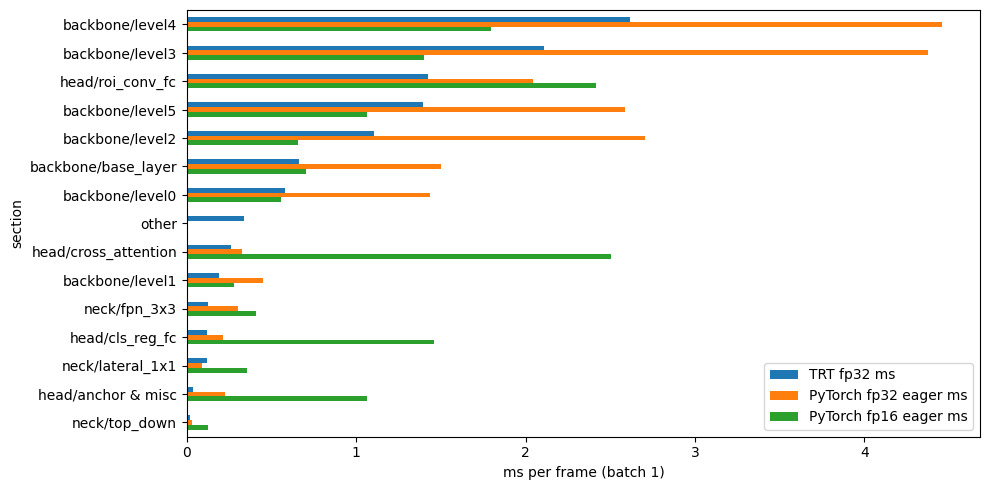

Slowest TensorRT fp16 layers:


,layer,ms,section
0,/m/backbone/model/base_layer/base_layer.0/Conv...,0.6647,backbone/base_layer
1,/m/backbone/model/level0/level0.0/Conv + /m/ba...,0.5800,backbone/level0
60,/m/backbone/model/level5/tree2/conv2/Conv + /m...,0.3521,backbone/level5
58,/m/backbone/model/level5/tree2/conv1/Conv + /m...,0.3492,backbone/level5
54,/m/backbone/model/level5/tree1/conv2/Conv,0.3468,backbone/level5
168,/m/bbox_head/attention/catconv.2/conv/Conv,0.3467,head/roi_conv_fc
42,/m/backbone/model/level4/tree2/tree2/conv2/Con...,0.3000,backbone/level4
35,/m/backbone/model/level4/tree1/tree2/conv2/Con...,0.3000,backbone/level4
40,/m/backbone/model/level4/tree2/tree1/conv2/Con...,0.2998,backbone/level4
32,/m/backbone/model/level4/tree1/tree1/conv2/Conv,0.2985,backbone/level4


In [25]:
RUN_TENSORRT = True
TRT_EVAL_PER_CATEGORY = 60   # images per category for the quick TensorRT-vs-PyTorch F1 check (0 = skip)
import re

def onnx_name_to_section(name):
    rules = [(r"backbone/model/(base_layer|level\d)", lambda m: "backbone/" + m.group(1)),
             (r"neck/lateral_convs", lambda m: "neck/lateral_1x1"), (r"neck/fpn_convs", lambda m: "neck/fpn_3x3"),
             (r"/neck/", lambda m: "neck/top_down"),
             (r"bbox_head/attention/attention", lambda m: "head/cross_attention"),
             (r"bbox_head/attention/(convs|catconv|fc)", lambda m: "head/roi_conv_fc"),
             (r"bbox_head/(cls_modules|reg_modules|cls_layers|reg_layers)", lambda m: "head/cls_reg_fc"),
             (r"GridSample|grid_sample", lambda m: "head/roi_pool(grid_sample)"),
             (r"bbox_head", lambda m: "head/anchor & misc"), (r"[Rr]eformat|[Cc]opy", lambda m: "reformat/copy")]
    for pat, f in rules:
        m = re.search(pat, name)
        if m:
            return f(m)
    return "other"

def group_layer_profile(layer_ms):
    # layer_ms: {layer_name: ms per inference} -> DataFrame grouped by model part
    df = pd.DataFrame({"layer": list(layer_ms), "ms": list(layer_ms.values())})
    df["section"] = df.layer.map(onnx_name_to_section)
    g = df.groupby("section").ms.agg(["sum", "count"]).rename(columns={"sum": "ms", "count": "trt_layers"})
    g["share_%"] = 100 * g.ms / g.ms.sum()
    return g.sort_values("ms", ascending=False), df

TRT_RES = {}
if RUN_TENSORRT and DEVICE == "cuda":
    try:
        import tensorrt as trt
    except ImportError:
        cu_major = (torch.version.cuda or "12").split(".")[0]
        subprocess.run([sys.executable, "-m", "pip", "-q", "install", f"tensorrt-cu{cu_major}"], check=False)
        import tensorrt as trt
    print("TensorRT", trt.__version__)
    TRT_LOGGER = trt.Logger(trt.Logger.WARNING)

    def build_engine(onnx_path, fp16):
        builder = trt.Builder(TRT_LOGGER)
        flags = 0
        if int(trt.__version__.split(".")[0]) < 10:
            flags = 1 << int(trt.NetworkDefinitionCreationFlag.EXPLICIT_BATCH)
        network = builder.create_network(flags)
        parser = trt.OnnxParser(network, TRT_LOGGER)
        with open(onnx_path, "rb") as f:
            if not parser.parse(f.read()):
                raise RuntimeError("\n".join(str(parser.get_error(i)) for i in range(parser.num_errors)))
        config = builder.create_builder_config()
        config.set_memory_pool_limit(trt.MemoryPoolType.WORKSPACE, 2 << 30)
        config.profiling_verbosity = trt.ProfilingVerbosity.DETAILED
        if fp16:
            config.set_flag(trt.BuilderFlag.FP16)
        t0 = time.time()
        ser = builder.build_serialized_network(network, config)
        if ser is None:
            raise RuntimeError("engine build failed")
        print(f"  built {'fp16' if fp16 else 'fp32'} engine in {time.time()-t0:.0f}s ({ser.nbytes/2**20:.1f} MB)")
        return trt.Runtime(TRT_LOGGER).deserialize_cuda_engine(ser)

    class TRTRunner:
        def __init__(self, engine):
            self.engine, self.ctx = engine, engine.create_execution_context()
            self.stream = torch.cuda.Stream()
            self.bufs = {}
            for i in range(engine.num_io_tensors):
                n = engine.get_tensor_name(i)
                dt = torch.from_numpy(np.empty(0, dtype=trt.nptype(engine.get_tensor_dtype(n)))).dtype
                self.bufs[n] = torch.empty(tuple(engine.get_tensor_shape(n)), dtype=dt, device="cuda")
                self.ctx.set_tensor_address(n, self.bufs[n].data_ptr())
        def __call__(self, x):
            cur = torch.cuda.current_stream()
            self.stream.wait_stream(cur)
            with torch.cuda.stream(self.stream):
                self.bufs["image"].copy_(x)
                self.ctx.execute_async_v3(self.stream.cuda_stream)
            cur.wait_stream(self.stream)
            return [self.bufs[n] for n in IO_NAMES["output_names"]]

    class LayerProfiler(trt.IProfiler):
        def __init__(self):
            trt.IProfiler.__init__(self); self.t = defaultdict(list)
        def report_layer_time(self, layer_name, ms):
            self.t[layer_name].append(ms)

    for fp16 in (False, True):
        tag = "fp16" if fp16 else "fp32"
        try:
            eng = build_engine(ONNX_PATH, fp16)
            run = TRTRunner(eng)
            r = dict(latency=stats(cuda_timeit(lambda: run(X1))))
            with torch.inference_mode():
                ref = [t.float() for t in model(X1)]
            out = [t.float() for t in run(X1)]
            r["max_abs_diff_vs_torch_fp32"] = {n: (a - b).abs().max().item() for n, a, b in zip(IO_NAMES["output_names"], out, ref)}
            prof = LayerProfiler(); run.ctx.profiler = prof
            for _ in range(50):
                run(X1); torch.cuda.synchronize()
            run.ctx.profiler = None
            layer_ms = {k: float(np.mean(v)) for k, v in prof.t.items()}
            r["by_section"], r["layers"] = group_layer_profile(layer_ms)
            try:
                info = eng.create_engine_inspector().get_engine_information(trt.LayerInformationFormat.JSON)
                with open(os.path.join(RESULTS_DIR, f"trt_engine_layers_{tag}.json"), "w") as f:
                    f.write(info)
            except Exception:
                pass
            r["runner"] = run
            TRT_RES[tag] = r
            print(f"[TensorRT {tag}] mean {r['latency']['mean_ms']:.3f} ms ({r['latency']['fps']:.0f} FPS) | "
                  f"sum of per-layer times {sum(layer_ms.values()):.3f} ms | max diff vs PyTorch: "
                  + ", ".join(f"{k} {v:.1e}" for k, v in r["max_abs_diff_vs_torch_fp32"].items()))
        except Exception as ex:
            print(f"TensorRT {tag} failed:", repr(ex)[:400])

    if TRT_RES:
        comp = pd.concat({f"TRT {t} ms": TRT_RES[t]["by_section"].ms for t in TRT_RES}, axis=1)
        pt = SEC["fp32"][SEC["fp32"].is_leaf].copy()
        pt["grp"] = pt.section.map(lambda s: s if not s.startswith("head/stage") else "head/" + s.split("/")[-1])
        pt["grp"] = pt.grp.replace({"head/anchor_decode": "head/anchor & misc", "head/anchor_init": "head/anchor & misc"})
        comp["PyTorch fp32 eager ms"] = pt.groupby("grp").ms.sum()
        comp["PyTorch fp16 eager ms"] = SEC["fp16"][SEC["fp16"].is_leaf].assign(grp=pt.grp.values).groupby("grp").ms.sum()
        comp = comp.fillna(0).sort_values(comp.columns[0], ascending=False)
        print("Per-part time: TensorRT per-layer profile vs PyTorch sections (same GPU)")
        display(comp.round(3))
        comp.to_csv(os.path.join(RESULTS_DIR, "tensorrt_vs_pytorch_by_part.csv"))
        ax = comp.plot.barh(figsize=(10, 5)); ax.invert_yaxis(); ax.set_xlabel("ms per frame (batch 1)")
        plt.tight_layout(); plt.savefig(os.path.join(RESULTS_DIR, "tensorrt_vs_pytorch_by_part.png"), dpi=150); plt.show()
        print("Slowest TensorRT fp16 layers:")
        display(TRT_RES.get("fp16", TRT_RES.get("fp32"))["layers"].sort_values("ms", ascending=False).head(15)
                .assign(layer=lambda d: d.layer.str.slice(0, 110)).round(4))

In [26]:
# quick accuracy check of the TensorRT engines on a stratified subset (same images for all back-ends)
if TRT_RES and TRT_EVAL_PER_CATEGORY:
    rng = random.Random(1); ev = set(EVAL_LIST)
    SUB = sorted({p for c in CATEGORIES for p in rng.sample([q for q in CAT_LISTS[c] if q in ev],
                                                               min(TRT_EVAL_PER_CATEGORY, len([q for q in CAT_LISTS[c] if q in ev])))})
    def predict_with(run_fn, rels, out_dir):
        shutil.rmtree(out_dir, ignore_errors=True)
        for rel in tqdm(rels, desc=out_dir.split("/")[-1]):
            x = torch.from_numpy(preprocess_bgr(cv2.imread(os.path.join(LOCAL_DATA, rel))))[None].to(DEVICE)
            cls, ap, ln, xs = [o[0].float().cpu().numpy() for o in run_fn(x)]
            lanes, _ = decode_one(cls, ap, ln, xs)
            dst = os.path.join(out_dir, rel.replace(".jpg", ".lines.txt")); os.makedirs(os.path.dirname(dst), exist_ok=True)
            s = lanes_to_culane_string(lanes)
            with open(dst, "w") as f:
                if s:
                    print(s, file=f)
    split_dir = os.path.join(LOCAL_DATA, "list", "test_split")
    TRT_F1 = {}
    for tag in TRT_RES:
        predict_with(TRT_RES[tag]["runner"], SUB, f"/content/preds_trt_{tag}")
        TRT_F1[f"TensorRT {tag}"] = eval_predictions(f"/content/preds_trt_{tag}", LOCAL_DATA, SUB, split_dir, verbose=False)[(0.5, "all")]["F1"]
    for tag in ACC:
        TRT_F1[f"PyTorch {tag}"] = eval_predictions(f"/content/preds_{tag}", LOCAL_DATA, SUB, split_dir, verbose=False)[(0.5, "all")]["F1"]
    print(f"F1@0.5 on the same {len(SUB)}-image subset:", {k: round(100 * v, 2) for k, v in TRT_F1.items()})

preds_trt_fp32:   0%|          | 0/540 [00:00<?, ?it/s]

F1@0.5 on the same 540-image subset: {'TensorRT fp32': 80.47, 'PyTorch fp32': 80.47, 'PyTorch fp16': 80.47}


## 10. Summary (saved to Drive)

In [27]:
def _jsonable(o):
    if isinstance(o, (np.floating, np.integer)):
        return o.item()
    if isinstance(o, (pd.DataFrame, pd.Series)):
        return json.loads(o.to_json())
    if isinstance(o, dict):
        return {str(k): _jsonable(v) for k, v in o.items()}
    if isinstance(o, (list, tuple)):
        return [_jsonable(v) for v in o]
    return o

SUMMARY = OrderedDict(
    env=ENV, checkpoint=CKPT_PATH, n_images_evaluated=len(EVAL_LIST),
    accuracy={tag: {f"{k[1]}@{k[0]}": v for k, v in res.items()} for tag, res in ACC.items()},
    params_total=int(n_params), params_by_part=PARAMS_DF.params.to_dict(),
    gflops_total=float(CPLX.GFLOPs.sum()), gmacs_total=float(CPLX.GFLOPs.sum() / 2),
    traffic_unfused_MB={"fp32": float(CPLX["MB moved fp32 (unfused)"].sum()), "fp16": float(CPLX["MB moved fp16 (unfused)"].sum())},
    traffic_fused_MB={"fp32": float(LAYERS.bytes_fp32.sum() / 2**20), "fp16": float(LAYERS.bytes_fp16.sum() / 2**20)},
    network_latency_b1=LAT, pipeline_ms=PIPE, throughput=TPUT, gpu_memory=MEM,
    section_ms={t: SEC[t].set_index("section").ms.to_dict() for t in SEC},
    kernel_time_by_type_ms=CAT_DF.to_dict(), onnx=dict(static=ONNX_PATH, dynamic=ONNX_DYN_PATH, ops=dict(ONNX_OPS)),
    ort_latency=ORT_LAT,
    tensorrt={t: dict(latency=r["latency"], by_section_ms=r["by_section"].ms.to_dict()) for t, r in TRT_RES.items()},
)
with open(os.path.join(RESULTS_DIR, "summary.json"), "w") as f:
    json.dump(_jsonable(SUMMARY), f, indent=1)

f1 = {t: 100 * ACC[t][(0.5, "all")]["F1"] for t in ACC}
lines = [f"GPU: {ENV['gpu']} | torch {ENV['torch']} | images evaluated: {len(EVAL_LIST)}",
         "F1@0.5: " + ", ".join(f"{t} {v:.2f}" for t, v in f1.items()) + "  (README: 81.55)",
         f"Params: {n_params/1e6:.2f} M | {CPLX.GFLOPs.sum():.1f} GFLOPs ({CPLX.GFLOPs.sum()/2:.1f} GMACs) per 320x800 frame",
         f"Memory traffic per frame: {SUMMARY['traffic_unfused_MB']['fp32']:.0f} MB eager fp32, ~{SUMMARY['traffic_fused_MB']['fp16']:.0f} MB fused fp16",
         "Network latency b1: " + ", ".join(f"{k} {v['mean_ms']:.2f} ms" for k, v in LAT.items()),
         "TensorRT b1: " + (", ".join(f"{t} {r['latency']['mean_ms']:.2f} ms" for t, r in TRT_RES.items()) or "n/a"),
         "Largest parts (fp32 eager): " + ", ".join(f"{r['section']} {r['ms']:.2f} ms ({r['share_%']:.0f}%)" for _, r in
                                                    SEC["fp32"][SEC["fp32"].is_leaf].nlargest(5, "ms").iterrows())]
print("\n".join(lines))
print("\nSaved in", RESULTS_DIR, ":", sorted(os.listdir(RESULTS_DIR)))

GPU: Tesla T4 | torch 2.11.0+cu130 | images evaluated: 34680
F1@0.5: fp32 81.54, fp16 81.54  (README: 81.55)
Params: 15.83 M | 0.0 GFLOPs (0.0 GMACs) per 320x800 frame
Memory traffic per frame: 930 MB eager fp32, ~161 MB fused fp16
Network latency b1: fp32 eager 19.56 ms, fp32 CUDA graph 19.98 ms, fp16 eager 14.11 ms, fp16 CUDA graph 7.44 ms
TensorRT b1: fp32 11.20 ms
Largest parts (fp32 eager): backbone/level4 4.46 ms (21%), backbone/level3 4.38 ms (21%), backbone/level2 2.71 ms (13%), backbone/level5 2.58 ms (12%), backbone/base_layer 1.50 ms (7%)

Saved in /content/drive/MyDrive/clrernet_profiling : ['accuracy_culane.csv', 'accuracy_per_category.png', 'clrernet_dla34_culane_ema_b1_op17.onnx', 'clrernet_dla34_culane_ema_dynbatch_op17.onnx', 'clrernet_profiled_graph.dot', 'clrernet_profiled_graph.png', 'complexity_per_section.csv', 'kernel_categories.png', 'layers_roofline.csv', 'pipeline_breakdown.png', 'roofline.png', 'section_times.csv', 'section_times.png', 'summary.json', 'tensor

## 11. Next: the same measurements on the Jetson Orin Nano
Copy `clrernet_dla34_culane_ema_b1_op17.onnx` (and `clrernet_post.py` for decoding) to the Jetson, then:

```bash
sudo nvpmodel -m 0        # MAXN / MAXN SUPER (JetPack 6.2); check with: sudo nvpmodel -q
sudo jetson_clocks        # lock clocks for stable numbers
/usr/src/tensorrt/bin/trtexec --onnx=clrernet_dla34_culane_ema_b1_op17.onnx --fp16 \
    --saveEngine=clrernet_fp16.engine --useCudaGraph --useSpinWait --warmUp=500 --iterations=1000 \
    --separateProfileRun --dumpProfile --exportProfile=profile_fp16.json \
    --exportLayerInfo=layers_fp16.json --profilingVerbosity=detailed
# same with no --fp16 for FP32; run `tegrastats` in another terminal for power / EMC (memory-bandwidth) utilisation
```

Then group the Jetson's per-layer profile into the same parts as here:

```python
import json, pandas as pd
prof = json.load(open("profile_fp16.json"))
layer_ms = {p["name"]: p["averageMs"] for p in prof if "name" in p}
by_part, layers = group_layer_profile(layer_ms)   # function from section 9 of this notebook
```

What to look at when comparing Colab vs Jetson:
* parts whose share **grows** on the Jetson are bandwidth-bound (see the roofline table: the full-resolution `base_layer`/`level0`, element-wise traffic, `grid_sample`);
* the gap between eager and CUDA-graph latency here is the launch overhead; on the Jetson's ARM CPU it is larger, so prefer TensorRT + CUDA graph (`--useCudaGraph`) or at least a single engine call per frame;
* the CPU-side steps (JPEG decode, cv2 resize, lane decode) from the pipeline breakdown can become the bottleneck on the Orin Nano – the GPU preprocessing variant above shows how much can move to the GPU.